In [6]:
##Exploratory Data Analysis

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load processed dataset
df = pd.read_csv(
    r"C:\Users\preet\OneDrive\Desktop\PROJECT 2027\P2\Data\Processed\r612_payment_system_indicators.csv",
    parse_dates=["Date"]
)

# Ensure chronological order
df = df.sort_values("Date").reset_index(drop=True)

# Display dataset
display(df.head())

,Date,IMPS_Volume_Lakh,IMPS_Value_Crore,NEFT_Volume_Lakh,NEFT_Value_Crore,UPI_Volume_Lakh,UPI_Value_Crore
0,2019-11-01,2280.75,202903.64,2194.59,1734651.23,12187.71,189229.09
1,2019-12-01,2564.67,210934.23,2336.88,1942230.71,13084.02,202520.76
2,2020-01-01,2595.26,216810.70,2605.55,1929463.51,13050.19,216242.97
3,2020-02-01,2477.98,214565.66,2483.57,1870493.56,13256.93,222516.95
4,2020-03-01,2168.23,201961.70,2623.70,2283664.64,12468.45,206462.31


In [8]:
# Summary statistics
summary = df.describe().T

summary["missing_values"] = df.isnull().sum()
summary["unique_values"] = df.nunique()

display(summary)

,count,mean,min,25%,50%,75%,max,std,missing_values,unique_values
Date,82,2023-03-17 13:27:48.292683008,2019-11-01 00:00:00,2021-07-08 18:00:00,2023-03-16 12:00:00,2024-11-23 12:00:00,2026-08-01 00:00:00,NaN,0,82
IMPS_Volume_Lakh,82.0,4045.734146,1224.75,3543.6175,4354.22,4741.0525,5806.36,963.666235,0,82
IMPS_Value_Crore,82.0,469980.815854,121140.79,321176.2725,503989.6,600549.0425,740176.18,161128.484532,0,82
NEFT_Volume_Lakh,82.0,5481.276951,1759.79,3253.9325,4875.735,7972.1975,9390.43,2419.391251,0,82
NEFT_Value_Crore,82.0,3089521.789634,1306406.41,2340789.545,3042909.59,3780130.3525,5661604.25,901790.931938,0,82
UPI_Volume_Lakh,82.0,101640.289878,9995.74,33230.1275,87574.47,164652.7275,245089.58,73024.034671,0,82
UPI_Value_Crore,82.0,1459787.056341,151140.66,614191.6375,1410227.65,2292645.38,2990424.18,904190.215752,0,82


In [9]:
##monthly growth rates

In [10]:
growth_df = df.copy()

indicators = [
    "IMPS_Volume_Lakh",
    "NEFT_Volume_Lakh",
    "UPI_Volume_Lakh",
    "IMPS_Value_Crore",
    "NEFT_Value_Crore",
    "UPI_Value_Crore"
]

for col in indicators:
    growth_df[f"{col}_MoM_Growth_%"] = (
        growth_df[col].pct_change() * 100
    )

display(growth_df.head(12))

,Date,IMPS_Volume_Lakh,IMPS_Value_Crore,NEFT_Volume_Lakh,NEFT_Value_Crore,UPI_Volume_Lakh,UPI_Value_Crore,IMPS_Volume_Lakh_MoM_Growth_%,NEFT_Volume_Lakh_MoM_Growth_%,UPI_Volume_Lakh_MoM_Growth_%,IMPS_Value_Crore_MoM_Growth_%,NEFT_Value_Crore_MoM_Growth_%,UPI_Value_Crore_MoM_Growth_%
0,2019-11-01,2280.75,202903.64,2194.59,1734651.23,12187.71,189229.09,NaN,NaN,NaN,NaN,NaN,NaN
1,2019-12-01,2564.67,210934.23,2336.88,1942230.71,13084.02,202520.76,12.448537,6.483671,7.354212,3.957834,11.966641,7.024116
2,2020-01-01,2595.26,216810.70,2605.55,1929463.51,13050.19,216242.97,1.192746,11.496953,-0.258560,2.785925,-0.657347,6.775705
3,2020-02-01,2477.98,214565.66,2483.57,1870493.56,13256.93,222516.95,-4.519008,-4.681545,1.584191,-1.035484,-3.056287,2.901357
4,2020-03-01,2168.23,201961.70,2623.70,2283664.64,12468.45,206462.31,-12.500101,5.642281,-5.947682,-5.874174,22.088880,-7.215019
5,2020-04-01,1224.75,121140.79,1759.79,1306406.41,9995.74,151140.66,-43.513834,-32.927164,-19.831735,-40.017939,-42.793421,-26.795036
6,2020-05-01,1666.80,169401.68,1929.39,1481749.52,12344.97,218391.60,36.093080,9.637514,23.502312,39.838679,13.421789,44.495598
7,2020-06-01,1989.12,206950.80,2274.01,1906586.12,13369.31,261835.00,19.337653,17.861604,8.297631,22.165731,28.671283,19.892432
8,2020-07-01,2220.99,225775.28,2401.03,1963113.39,14973.54,290537.86,11.656914,5.585727,11.999348,9.096114,2.964842,10.962194
9,2020-08-01,2461.25,235136.91,2346.09,1930552.38,16188.28,298307.61,10.817698,-2.288185,8.112577,4.146437,-1.658641,2.674264


In [11]:
##Plot transaction volumes

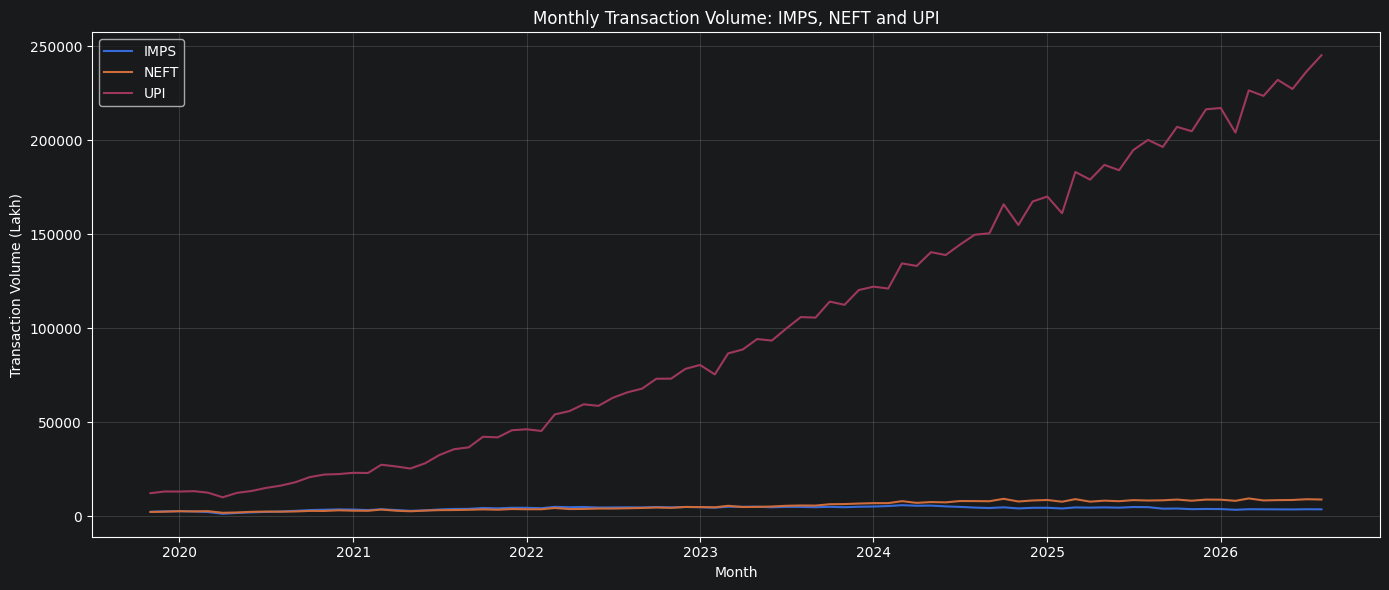

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["IMPS_Volume_Lakh"], label="IMPS")
plt.plot(df["Date"], df["NEFT_Volume_Lakh"], label="NEFT")
plt.plot(df["Date"], df["UPI_Volume_Lakh"], label="UPI")

plt.title("Monthly Transaction Volume: IMPS, NEFT and UPI")
plt.xlabel("Month")
plt.ylabel("Transaction Volume (Lakh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
##Plot transaction values

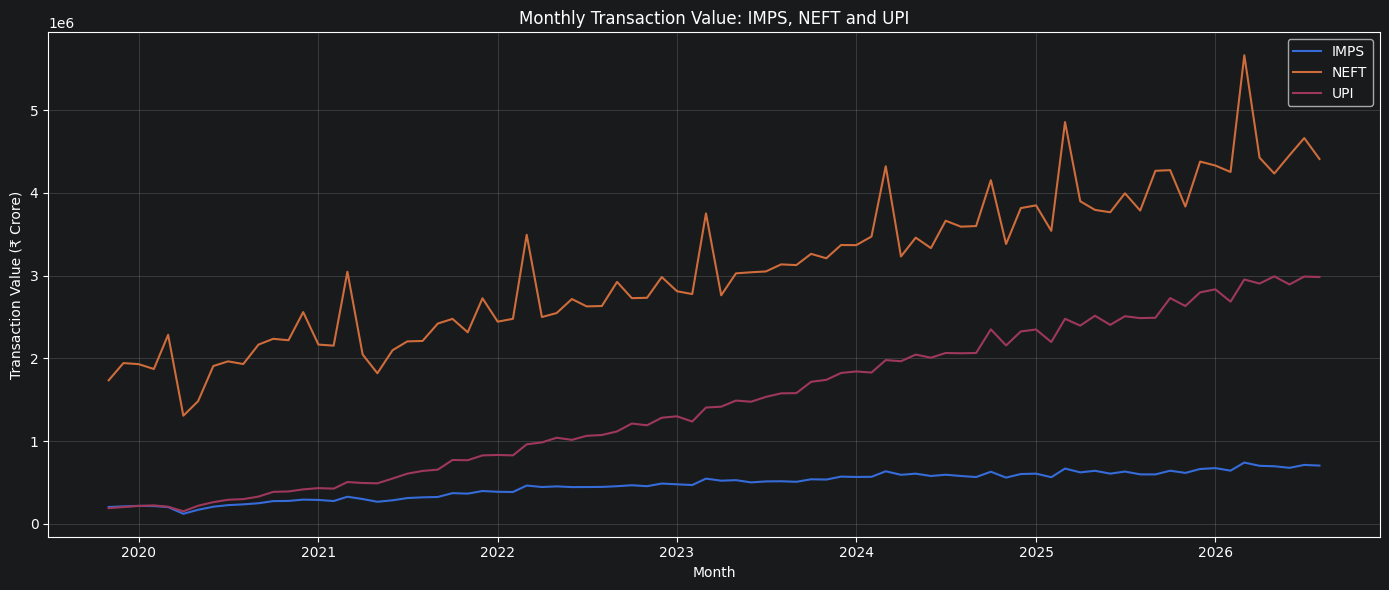

In [14]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["IMPS_Value_Crore"], label="IMPS")
plt.plot(df["Date"], df["NEFT_Value_Crore"], label="NEFT")
plt.plot(df["Date"], df["UPI_Value_Crore"], label="UPI")

plt.title("Monthly Transaction Value: IMPS, NEFT and UPI")
plt.xlabel("Month")
plt.ylabel("Transaction Value (₹ Crore)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
##Comparing payment systems

In [16]:
latest = df.iloc[-1]

print("Latest observation:", latest["Date"].strftime("%B %Y"))

print("\nTransaction volumes (Lakh):")
print(latest[[
    "IMPS_Volume_Lakh",
    "NEFT_Volume_Lakh",
    "UPI_Volume_Lakh"
]])

print("\nTransaction values (₹ Crore):")
print(latest[[
    "IMPS_Value_Crore",
    "NEFT_Value_Crore",
    "UPI_Value_Crore"
]])

Latest observation: August 2026

Transaction volumes (Lakh):
IMPS_Volume_Lakh      3599.42
NEFT_Volume_Lakh      8825.02
UPI_Volume_Lakh     245089.58
Name: 81, dtype: object

Transaction values (₹ Crore):
IMPS_Value_Crore     703724.01
NEFT_Value_Crore     4408551.6
UPI_Value_Crore     2982355.93
Name: 81, dtype: object


In [17]:
##average transaction values for every month

In [18]:
avg_value_df = df[["Date"]].copy()

systems = ["IMPS", "NEFT", "UPI"]

for system in systems:
    avg_value_df[f"{system}_Average_Value_Rs"] = (
        df[f"{system}_Value_Crore"]
        / df[f"{system}_Volume_Lakh"]
    ) * 100

display(avg_value_df.tail(12))

,Date,IMPS_Average_Value_Rs,NEFT_Average_Value_Rs,UPI_Average_Value_Rs
70,2025-09-01,15133.844094,50758.105057,1268.110636
71,2025-10-01,15906.409507,48613.609761,1317.714661
72,2025-11-01,16674.576005,46900.068868,1285.794372
73,2025-12-01,17436.019509,49864.642988,1292.699620
74,2026-01-01,17992.782455,49625.421815,1305.544470
75,2026-02-01,19115.786859,52338.027964,1316.173915
76,2026-03-01,20241.145376,60291.214034,1304.062518
77,2026-04-01,19336.118813,53111.902330,1299.062255
78,2026-05-01,19427.734106,49817.171495,1288.868830
79,2026-06-01,19115.812702,51893.746315,1273.168805


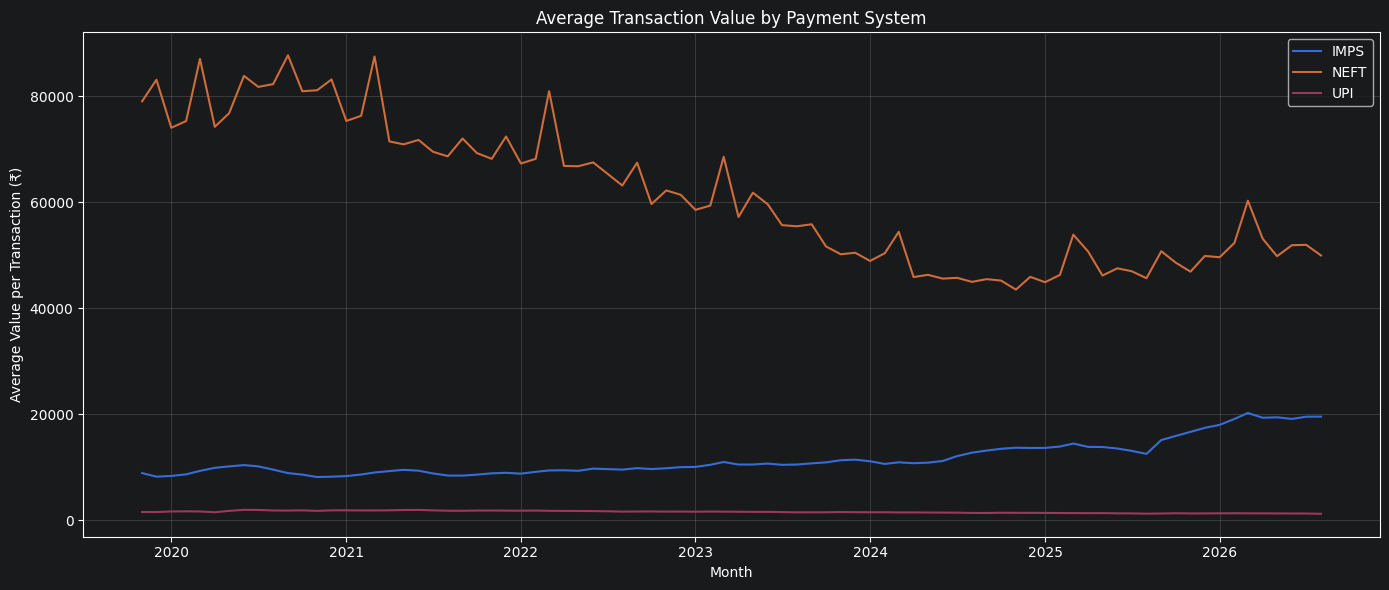

In [19]:
plt.figure(figsize=(14, 6))

for system in systems:
    plt.plot(
        avg_value_df["Date"],
        avg_value_df[f"{system}_Average_Value_Rs"],
        label=system
    )

plt.title("Average Transaction Value by Payment System")
plt.xlabel("Month")
plt.ylabel("Average Value per Transaction (₹)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
volume_columns = [
    "IMPS_Volume_Lakh",
    "NEFT_Volume_Lakh",
    "UPI_Volume_Lakh"
]

volume_shares = (
    df[volume_columns]
    .div(df[volume_columns].sum(axis=1), axis=0)
    * 100
)

volume_shares.columns = ["IMPS_Share_%", "NEFT_Share_%", "UPI_Share_%"]

volume_shares.insert(0, "Date", df["Date"])

display(volume_shares.tail(12))

,Date,IMPS_Share_%,NEFT_Share_%,UPI_Share_%
70,2025-09-01,1.889862,4.026814,94.083323
71,2025-10-01,1.835859,3.998875,94.165266
72,2025-11-01,1.703801,3.775405,94.520795
73,2025-12-01,1.659650,3.834284,94.506066
74,2026-01-01,1.629781,3.801411,94.568808
75,2026-02-01,1.560151,3.770435,94.669414
76,2026-03-01,1.527109,3.921530,94.551360
77,2026-04-01,1.539724,3.538507,94.921769
78,2026-05-01,1.467030,3.480709,95.052261
79,2026-06-01,1.479082,3.586686,94.934231


In [21]:
value_columns = [
    "IMPS_Value_Crore",
    "NEFT_Value_Crore",
    "UPI_Value_Crore"
]

value_shares = (
    df[value_columns]
    .div(df[value_columns].sum(axis=1), axis=0)
    * 100
)

value_shares.columns = ["IMPS_Value_Share_%", "NEFT_Value_Share_%", "UPI_Value_Share_%"]

value_shares.insert(0, "Date", df["Date"])

display(value_shares.tail(12))

,Date,IMPS_Value_Share_%,NEFT_Value_Share_%,UPI_Value_Share_%
70,2025-09-01,8.118276,58.016483,33.865241
71,2025-10-01,8.398969,55.912670,35.688361
72,2025-11-01,8.687823,54.146996,37.165182
73,2025-12-01,8.453876,55.855894,35.690230
74,2026-01-01,8.588549,55.251160,36.160291
75,2026-02-01,8.478321,56.099607,35.422072
76,2026-03-01,7.912665,60.523937,31.563398
77,2026-04-01,8.730406,55.110465,36.159129
78,2026-05-01,8.785509,53.450587,37.763904
79,2026-06-01,8.433218,55.515805,36.050977


In [22]:
# Create a copy for growth analysis
trend_df = df.copy()

indicators = [
    "IMPS_Volume_Lakh",
    "NEFT_Volume_Lakh",
    "UPI_Volume_Lakh",
    "IMPS_Value_Crore",
    "NEFT_Value_Crore",
    "UPI_Value_Crore"
]

# Calculate YoY growth
for col in indicators:
    trend_df[f"{col}_YoY_Growth_%"] = (
        trend_df[col].pct_change(periods=12) * 100
    )

display(trend_df.tail(12))

,Date,IMPS_Volume_Lakh,IMPS_Value_Crore,NEFT_Volume_Lakh,NEFT_Value_Crore,UPI_Volume_Lakh,UPI_Value_Crore,IMPS_Volume_Lakh_YoY_Growth_%,NEFT_Volume_Lakh_YoY_Growth_%,UPI_Volume_Lakh_YoY_Growth_%,IMPS_Value_Crore_YoY_Growth_%,NEFT_Value_Crore_YoY_Growth_%,UPI_Value_Crore_YoY_Growth_%
70,2025-09-01,3943.79,596847.03,8403.21,4265310.16,196334.33,2489736.52,-8.270301,6.250988,30.526281,5.593161,18.550490,20.627079
71,2025-10-01,4035.88,641963.60,8790.97,4273607.85,207009.21,2727790.71,-13.545819,-4.273045,24.817386,1.999118,2.918295,16.085020
72,2025-11-01,3689.31,615176.80,8175.04,3834099.39,204669.79,2631632.64,-9.557558,5.219505,32.198367,10.182051,13.405244,22.106905
73,2025-12-01,3799.33,662451.92,8777.58,4376908.93,216346.68,2796712.71,-13.879419,5.664607,29.316535,10.124322,14.729960,20.304245
74,2026-01-01,3740.33,672989.44,8724.20,4329421.05,217034.45,2833481.26,-15.800623,1.823894,27.697362,10.977417,12.509979,20.674467
75,2026-02-01,3360.96,642473.95,8122.47,4251140.62,203941.84,2684229.30,-16.978280,6.204816,26.623244,14.099609,20.085211,22.205858
76,2026-03-01,3656.79,740176.18,9390.43,5661604.25,226411.08,2952542.03,-20.786805,4.234224,23.711707,10.835878,16.630500,19.187643
77,2026-04-01,3624.87,700909.17,8330.47,4424471.09,223467.97,2902988.05,-19.313394,8.363555,24.888322,12.746837,13.525177,21.214109
78,2026-05-01,3580.97,695701.33,8496.29,4232611.36,232019.28,2990424.18,-22.767330,3.418185,24.224215,8.556207,11.587042,18.936791
79,2026-06-01,3539.18,676543.02,8582.30,4453676.99,227160.66,2892138.66,-21.018958,8.355260,23.490397,11.575161,18.299674,20.308737


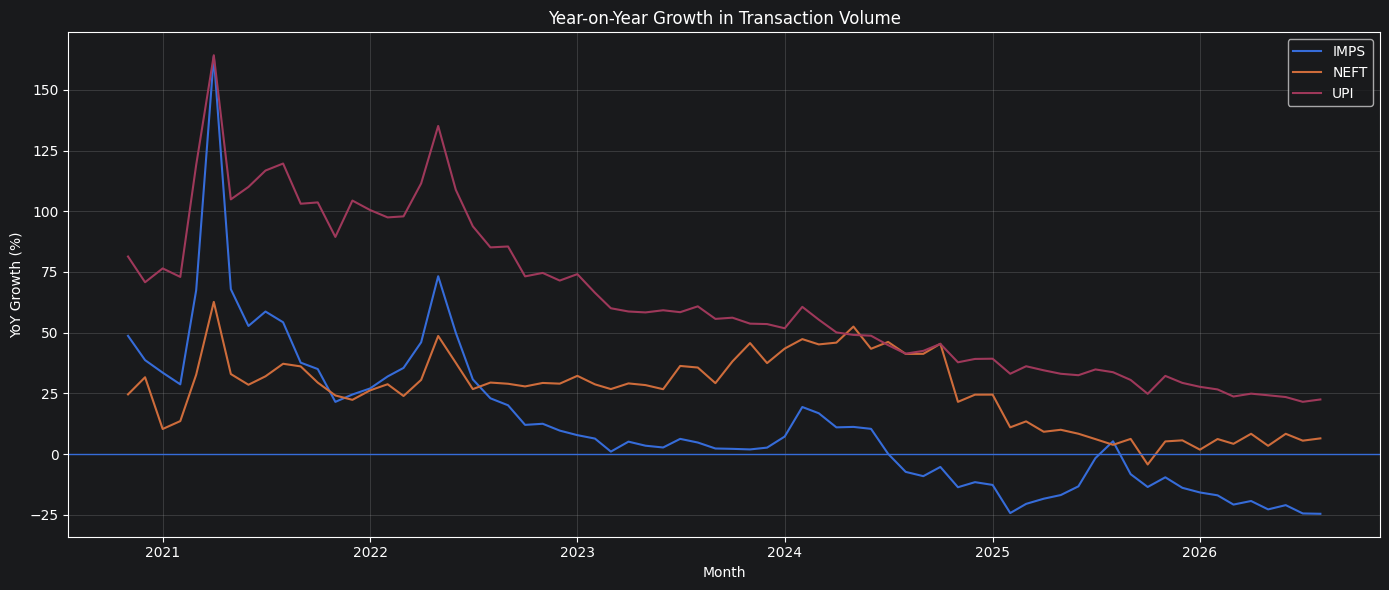

In [23]:
volume_growth_cols = [
    "IMPS_Volume_Lakh_YoY_Growth_%",
    "NEFT_Volume_Lakh_YoY_Growth_%",
    "UPI_Volume_Lakh_YoY_Growth_%"
]

plt.figure(figsize=(14, 6))

for col in volume_growth_cols:
    plt.plot(
        trend_df["Date"],
        trend_df[col],
        label=col.replace("_Volume_Lakh_YoY_Growth_%", "")
    )

plt.axhline(0, linewidth=1)
plt.title("Year-on-Year Growth in Transaction Volume")
plt.xlabel("Month")
plt.ylabel("YoY Growth (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

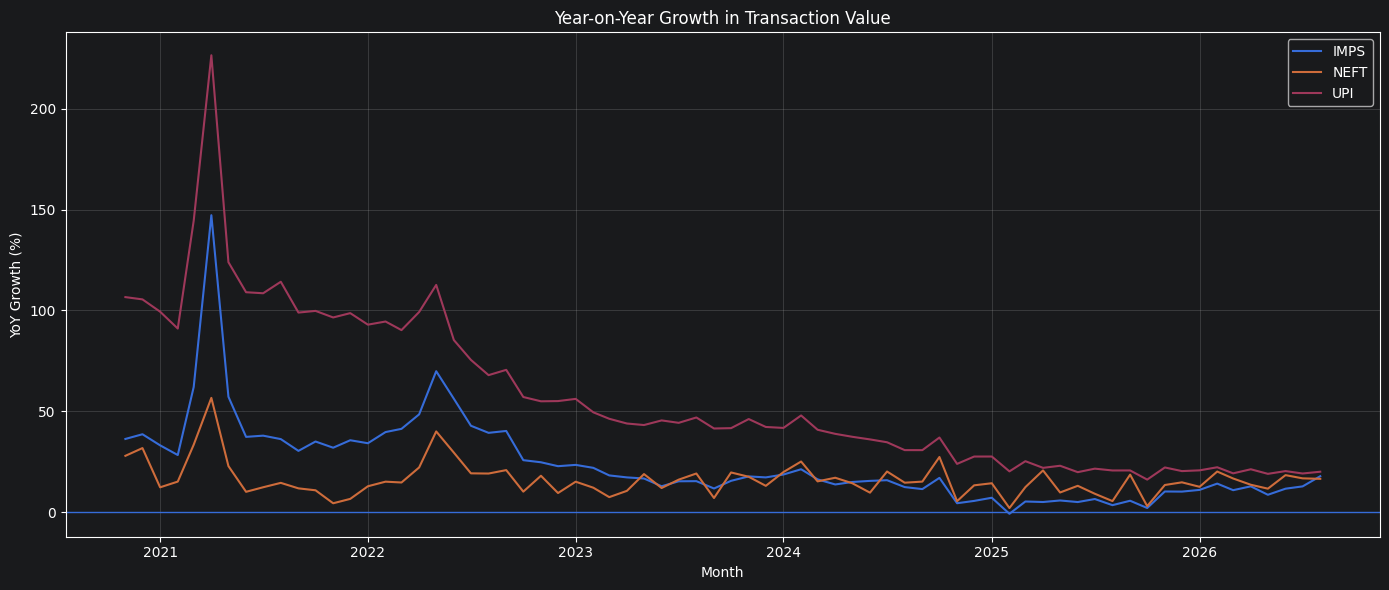

In [24]:
value_growth_cols = [
    "IMPS_Value_Crore_YoY_Growth_%",
    "NEFT_Value_Crore_YoY_Growth_%",
    "UPI_Value_Crore_YoY_Growth_%"
]

plt.figure(figsize=(14, 6))

for col in value_growth_cols:
    plt.plot(
        trend_df["Date"],
        trend_df[col],
        label=col.replace("_Value_Crore_YoY_Growth_%", "")
    )

plt.axhline(0, linewidth=1)
plt.title("Year-on-Year Growth in Transaction Value")
plt.xlabel("Month")
plt.ylabel("YoY Growth (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
growth_summary = pd.DataFrame({
    "Payment_System": ["IMPS", "NEFT", "UPI"],
    "Average_Volume_YoY_Growth_%": [
        trend_df["IMPS_Volume_Lakh_YoY_Growth_%"].mean(),
        trend_df["NEFT_Volume_Lakh_YoY_Growth_%"].mean(),
        trend_df["UPI_Volume_Lakh_YoY_Growth_%"].mean()
    ],
    "Average_Value_YoY_Growth_%": [
        trend_df["IMPS_Value_Crore_YoY_Growth_%"].mean(),
        trend_df["NEFT_Value_Crore_YoY_Growth_%"].mean(),
        trend_df["UPI_Value_Crore_YoY_Growth_%"].mean()
    ]
})

display(growth_summary.round(2))

,Payment_System,Average_Volume_YoY_Growth_%,Average_Value_YoY_Growth_%
0,IMPS,12.39,23.78
1,NEFT,26.02,16.10
2,UPI,63.46,56.77


In [26]:
years = (
    (df["Date"].iloc[-1] - df["Date"].iloc[0]).days / 365.25
)

cagr_results = []

for system in ["IMPS", "NEFT", "UPI"]:
    for metric in ["Volume_Lakh", "Value_Crore"]:

        col = f"{system}_{metric}"

        start_value = df[col].iloc[0]
        end_value = df[col].iloc[-1]

        cagr = (
            (end_value / start_value) ** (1 / years) - 1
        ) * 100

        cagr_results.append({
            "Payment_System": system,
            "Metric": metric,
            "Start_Value": start_value,
            "End_Value": end_value,
            "CAGR_%": cagr
        })

cagr_df = pd.DataFrame(cagr_results)

display(cagr_df.round(2))

,Payment_System,Metric,Start_Value,End_Value,CAGR_%
0,IMPS,Volume_Lakh,2280.75,3599.42,6.99
1,IMPS,Value_Crore,202903.64,703724.01,20.23
2,NEFT,Volume_Lakh,2194.59,8825.02,22.90
3,NEFT,Value_Crore,1734651.23,4408551.60,14.82
4,UPI,Volume_Lakh,12187.71,245089.58,56.00
5,UPI,Value_Crore,189229.09,2982355.93,50.47


In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_columns = [
    "IMPS_Volume_Lakh",
    "NEFT_Volume_Lakh",
    "UPI_Volume_Lakh",
    "IMPS_Value_Crore",
    "NEFT_Value_Crore",
    "UPI_Value_Crore"
]

correlation_matrix = df[correlation_columns].corr(method="pearson")

display(correlation_matrix.round(3))

,IMPS_Volume_Lakh,NEFT_Volume_Lakh,UPI_Volume_Lakh,IMPS_Value_Crore,NEFT_Value_Crore,UPI_Value_Crore
IMPS_Volume_Lakh,1.000,0.503,0.392,0.657,0.483,0.477
NEFT_Volume_Lakh,0.503,1.000,0.974,0.956,0.949,0.983
UPI_Volume_Lakh,0.392,0.974,1.000,0.941,0.937,0.994
IMPS_Value_Crore,0.657,0.956,0.941,1.000,0.945,0.969
NEFT_Value_Crore,0.483,0.949,0.937,0.945,1.000,0.945
UPI_Value_Crore,0.477,0.983,0.994,0.969,0.945,1.000


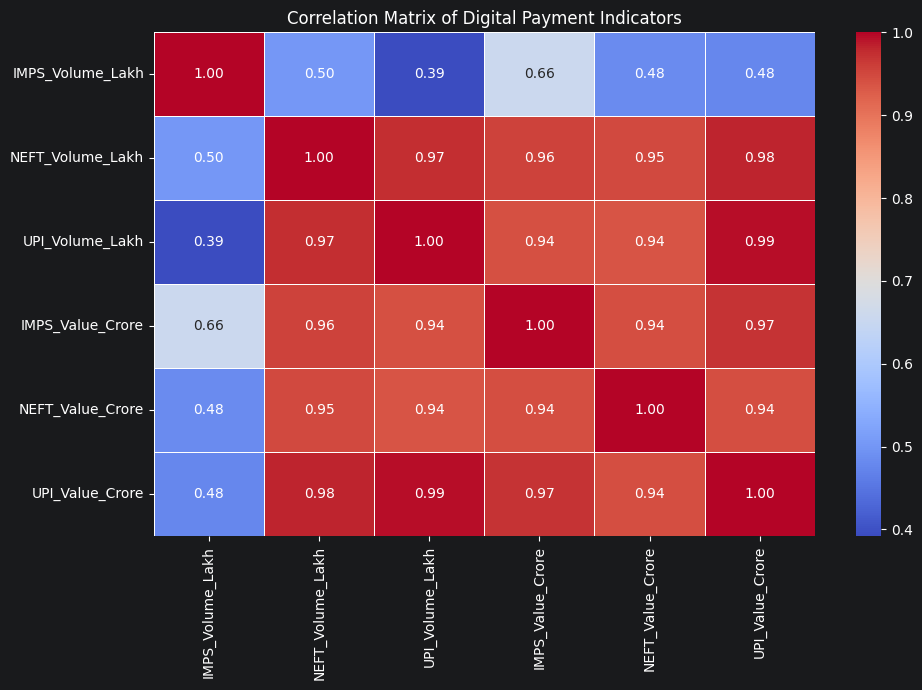

In [28]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Digital Payment Indicators")
plt.tight_layout()
plt.show()

In [29]:
pearson_corr = df[correlation_columns].corr(method="pearson")
spearman_corr = df[correlation_columns].corr(method="spearman")

print("PEARSON CORRELATION")
display(pearson_corr.round(3))

print("SPEARMAN CORRELATION")
display(spearman_corr.round(3))

PEARSON CORRELATION


,IMPS_Volume_Lakh,NEFT_Volume_Lakh,UPI_Volume_Lakh,IMPS_Value_Crore,NEFT_Value_Crore,UPI_Value_Crore
IMPS_Volume_Lakh,1.000,0.503,0.392,0.657,0.483,0.477
NEFT_Volume_Lakh,0.503,1.000,0.974,0.956,0.949,0.983
UPI_Volume_Lakh,0.392,0.974,1.000,0.941,0.937,0.994
IMPS_Value_Crore,0.657,0.956,0.941,1.000,0.945,0.969
NEFT_Value_Crore,0.483,0.949,0.937,0.945,1.000,0.945
UPI_Value_Crore,0.477,0.983,0.994,0.969,0.945,1.000


SPEARMAN CORRELATION


,IMPS_Volume_Lakh,NEFT_Volume_Lakh,UPI_Volume_Lakh,IMPS_Value_Crore,NEFT_Value_Crore,UPI_Value_Crore
IMPS_Volume_Lakh,1.000,0.459,0.425,0.473,0.436,0.426
NEFT_Volume_Lakh,0.459,1.000,0.982,0.983,0.973,0.983
UPI_Volume_Lakh,0.425,0.982,1.000,0.985,0.957,0.999
IMPS_Value_Crore,0.473,0.983,0.985,1.000,0.973,0.987
NEFT_Value_Crore,0.436,0.973,0.957,0.973,1.000,0.957
UPI_Value_Crore,0.426,0.983,0.999,0.987,0.957,1.000


In [30]:
growth_columns = [
    "IMPS_Volume_Lakh_YoY_Growth_%",
    "NEFT_Volume_Lakh_YoY_Growth_%",
    "UPI_Volume_Lakh_YoY_Growth_%",
    "IMPS_Value_Crore_YoY_Growth_%",
    "NEFT_Value_Crore_YoY_Growth_%",
    "UPI_Value_Crore_YoY_Growth_%"
]

growth_correlation = trend_df[growth_columns].corr(method="spearman")

display(growth_correlation.round(3))

,IMPS_Volume_Lakh_YoY_Growth_%,NEFT_Volume_Lakh_YoY_Growth_%,UPI_Volume_Lakh_YoY_Growth_%,IMPS_Value_Crore_YoY_Growth_%,NEFT_Value_Crore_YoY_Growth_%,UPI_Value_Crore_YoY_Growth_%
IMPS_Volume_Lakh_YoY_Growth_%,1.000,0.547,0.941,0.873,0.254,0.938
NEFT_Volume_Lakh_YoY_Growth_%,0.547,1.000,0.545,0.491,0.410,0.536
UPI_Volume_Lakh_YoY_Growth_%,0.941,0.545,1.000,0.887,0.198,0.973
IMPS_Value_Crore_YoY_Growth_%,0.873,0.491,0.887,1.000,0.405,0.907
NEFT_Value_Crore_YoY_Growth_%,0.254,0.410,0.198,0.405,1.000,0.246
UPI_Value_Crore_YoY_Growth_%,0.938,0.536,0.973,0.907,0.246,1.000


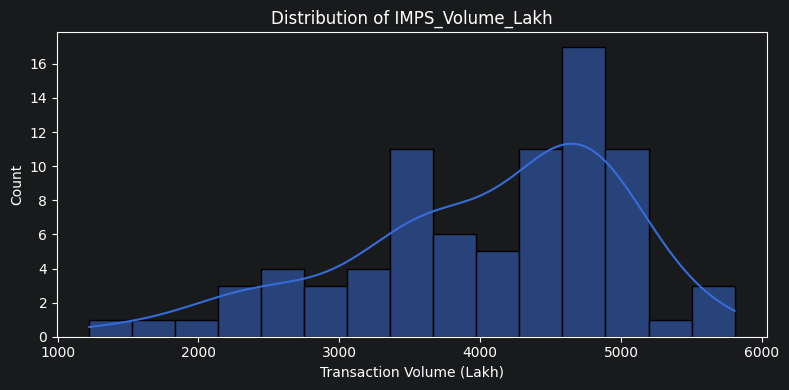

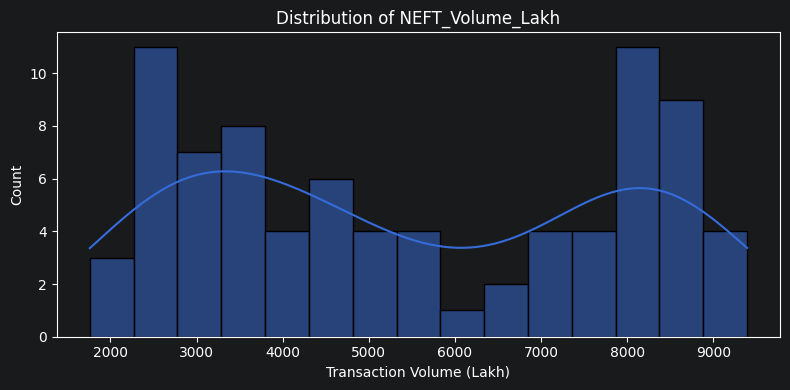

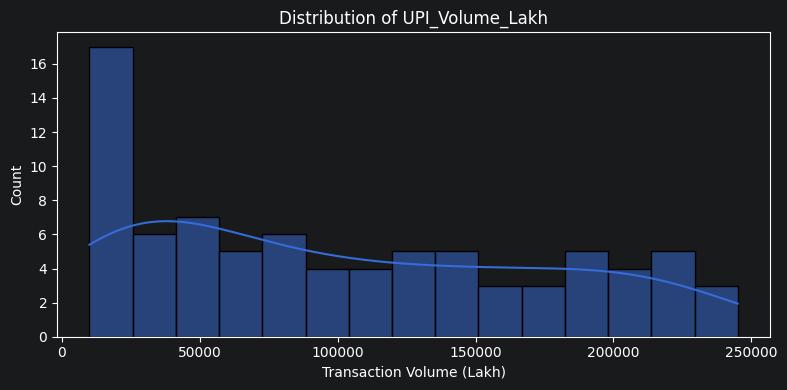

In [31]:
volume_columns = [
    "IMPS_Volume_Lakh",
    "NEFT_Volume_Lakh",
    "UPI_Volume_Lakh"
]

for col in volume_columns:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        df[col],
        kde=True,
        bins=15
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel("Transaction Volume (Lakh)")
    plt.tight_layout()
    plt.show()

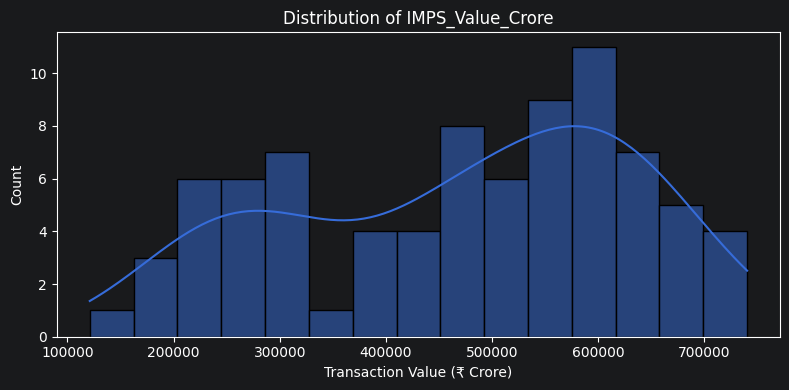

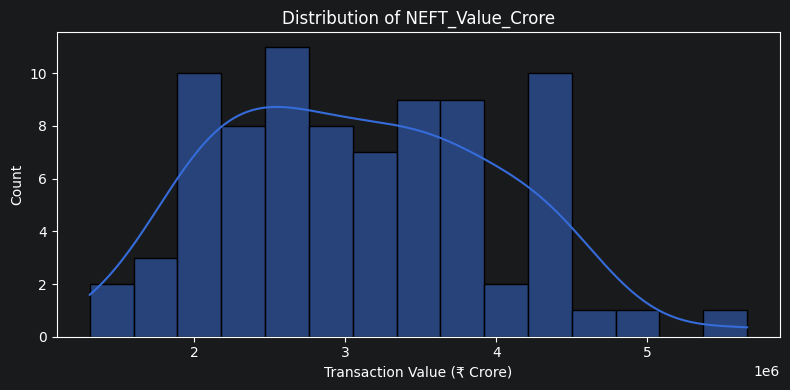

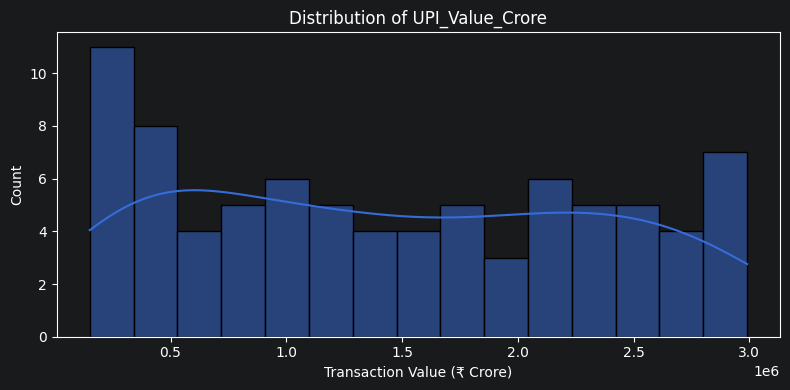

In [32]:
value_columns = [
    "IMPS_Value_Crore",
    "NEFT_Value_Crore",
    "UPI_Value_Crore"
]

for col in value_columns:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        df[col],
        kde=True,
        bins=15
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel("Transaction Value (₹ Crore)")
    plt.tight_layout()
    plt.show()

In [33]:
outlier_results = []

for col in correlation_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Indicator": col,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(2))

,Indicator,Lower_Bound,Upper_Bound,Outlier_Count
0,IMPS_Volume_Lakh,1747.46,6537.20,2
1,NEFT_Volume_Lakh,-3823.47,15049.60,0
2,UPI_Volume_Lakh,-163903.77,361786.63,0
3,IMPS_Value_Crore,-97882.88,1019608.20,0
4,NEFT_Value_Crore,181778.33,5939141.56,0
5,UPI_Value_Crore,-1903488.98,4810325.99,0


In [34]:
display(growth_correlation.round(3))

,IMPS_Volume_Lakh_YoY_Growth_%,NEFT_Volume_Lakh_YoY_Growth_%,UPI_Volume_Lakh_YoY_Growth_%,IMPS_Value_Crore_YoY_Growth_%,NEFT_Value_Crore_YoY_Growth_%,UPI_Value_Crore_YoY_Growth_%
IMPS_Volume_Lakh_YoY_Growth_%,1.000,0.547,0.941,0.873,0.254,0.938
NEFT_Volume_Lakh_YoY_Growth_%,0.547,1.000,0.545,0.491,0.410,0.536
UPI_Volume_Lakh_YoY_Growth_%,0.941,0.545,1.000,0.887,0.198,0.973
IMPS_Value_Crore_YoY_Growth_%,0.873,0.491,0.887,1.000,0.405,0.907
NEFT_Value_Crore_YoY_Growth_%,0.254,0.410,0.198,0.405,1.000,0.246
UPI_Value_Crore_YoY_Growth_%,0.938,0.536,0.973,0.907,0.246,1.000


In [35]:
##Time-Series Analysis

In [36]:
ts_df = df.copy()

ts_df = ts_df.set_index("Date").asfreq("MS")

print("Dataset shape:", ts_df.shape)
print("Frequency:", ts_df.index.freq)
print("Missing values:")
print(ts_df.isnull().sum())

Dataset shape: (82, 6)
Frequency: <MonthBegin>
Missing values:
IMPS_Volume_Lakh    0
IMPS_Value_Crore    0
NEFT_Volume_Lakh    0
NEFT_Value_Crore    0
UPI_Volume_Lakh     0
UPI_Value_Crore     0
dtype: int64


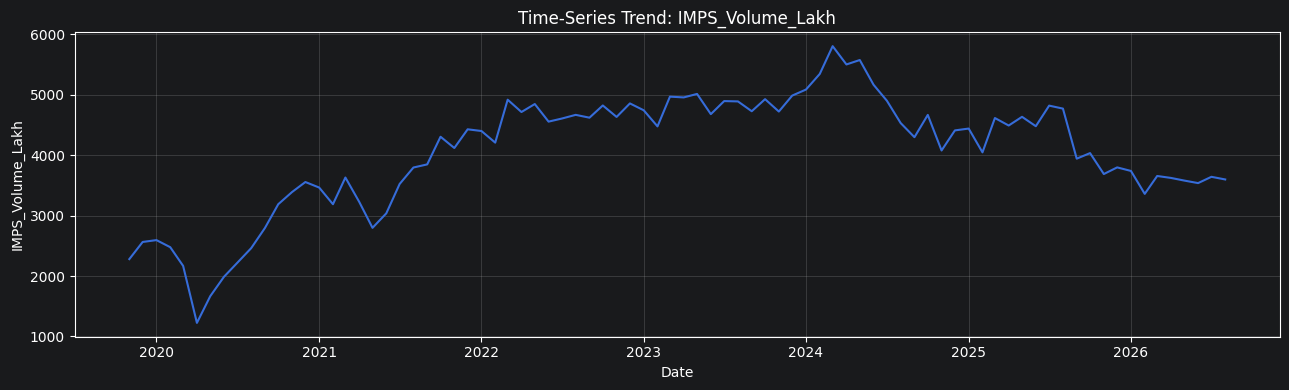

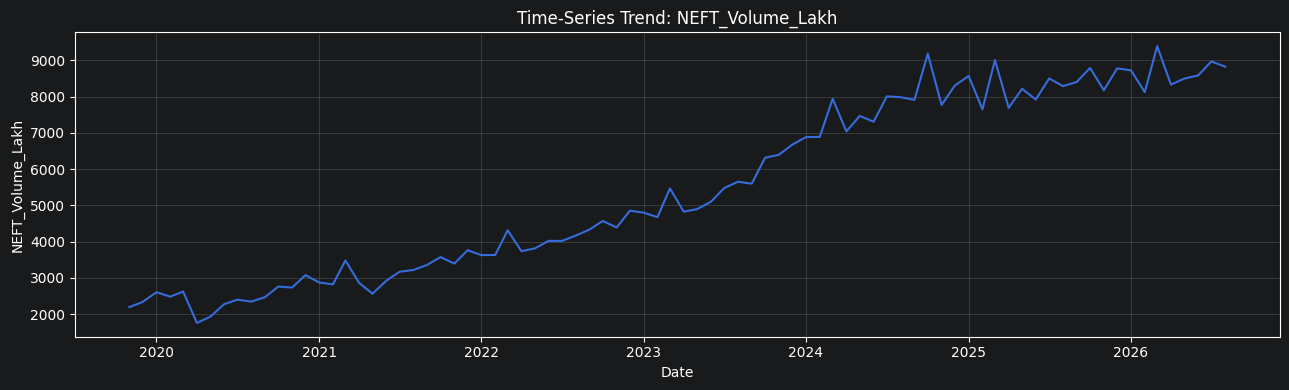

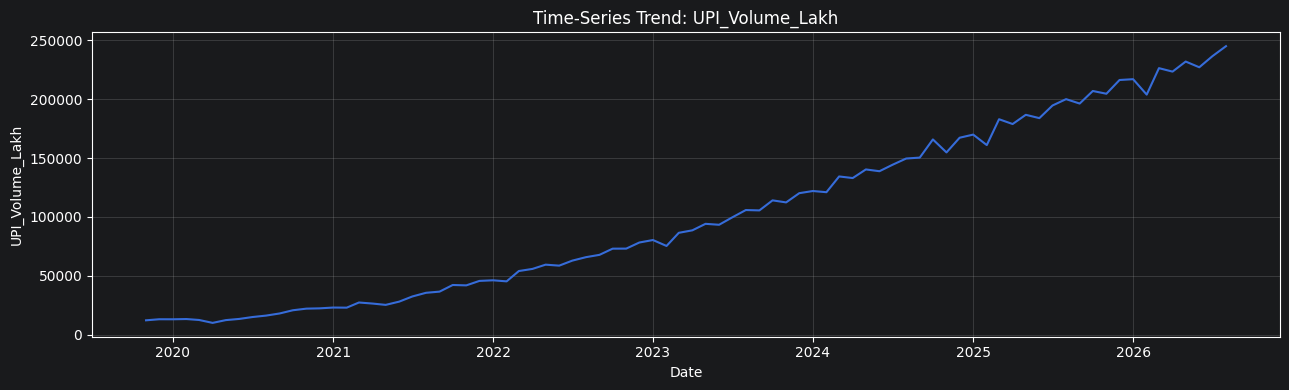

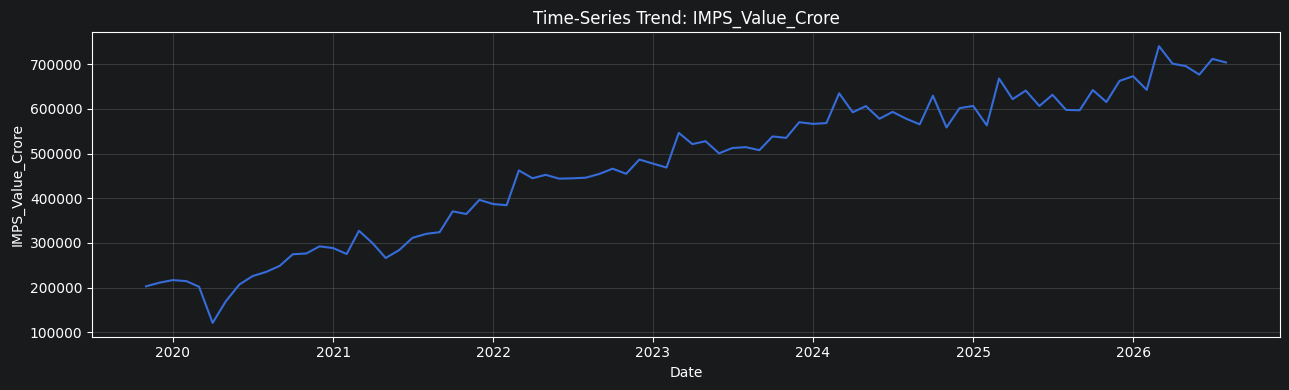

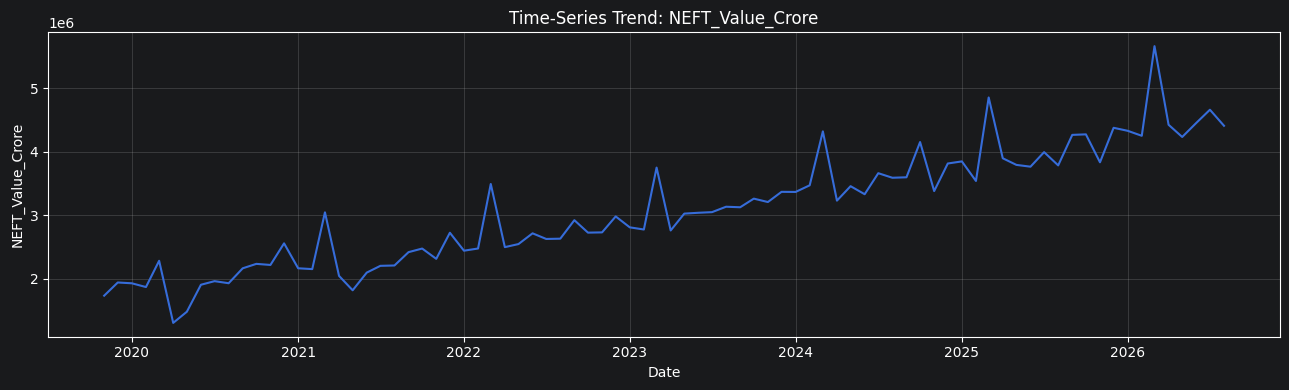

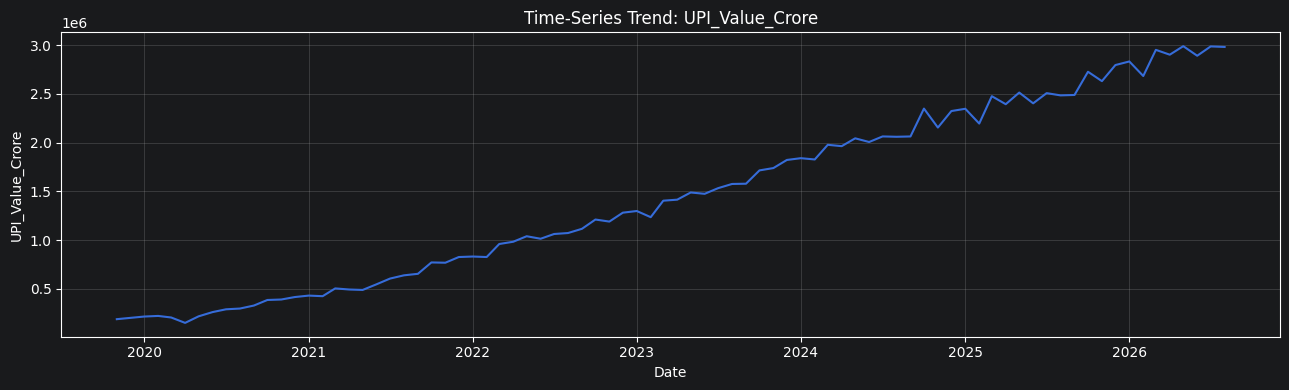

In [37]:
#long term trends
indicators = [
    "IMPS_Volume_Lakh",
    "NEFT_Volume_Lakh",
    "UPI_Volume_Lakh",
    "IMPS_Value_Crore",
    "NEFT_Value_Crore",
    "UPI_Value_Crore"
]

for col in indicators:

    plt.figure(figsize=(13, 4))

    plt.plot(ts_df.index, ts_df[col])

    plt.title(f"Time-Series Trend: {col}")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

In [38]:
###Augmented Dickey-Fuller (ADF) tests

In [39]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [40]:
from statsmodels.tsa.stattools import adfuller

adf_results = []

for col in indicators:

    result = adfuller(ts_df[col].dropna())

    adf_results.append({
        "Indicator": col,
        "ADF_Statistic": result[0],
        "P_Value": result[1],
        "Critical_Value_1%": result[4]["1%"],
        "Critical_Value_5%": result[4]["5%"],
        "Critical_Value_10%": result[4]["10%"],
        "Stationarity": (
            "Stationary" if result[1] < 0.05
            else "Non-stationary"
        )
    })

adf_df = pd.DataFrame(adf_results)

display(adf_df.round(4))

,Indicator,ADF_Statistic,P_Value,Critical_Value_1%,Critical_Value_5%,Critical_Value_10%,Stationarity
0,IMPS_Volume_Lakh,-1.2601,0.6472,-3.5289,-2.9044,-2.5897,Non-stationary
1,NEFT_Volume_Lakh,-0.8059,0.8174,-3.5289,-2.9044,-2.5897,Non-stationary
2,UPI_Volume_Lakh,0.0452,0.9621,-3.5289,-2.9044,-2.5897,Non-stationary
3,IMPS_Value_Crore,-1.9813,0.2948,-3.5289,-2.9044,-2.5897,Non-stationary
4,NEFT_Value_Crore,1.8991,0.9985,-3.5274,-2.9038,-2.5893,Non-stationary
5,UPI_Value_Crore,0.5744,0.9870,-3.5289,-2.9044,-2.5897,Non-stationary


In [41]:
#Testing first differences

In [42]:
diff_results = []

for col in indicators:

    differenced = ts_df[col].diff().dropna()

    result = adfuller(differenced)

    diff_results.append({
        "Indicator": col,
        "ADF_Statistic": result[0],
        "P_Value": result[1],
        "Stationarity": (
            "Stationary" if result[1] < 0.05
            else "Non-stationary"
        )
    })

diff_df = pd.DataFrame(diff_results)

display(diff_df.round(4))

,Indicator,ADF_Statistic,P_Value,Stationarity
0,IMPS_Volume_Lakh,-1.8561,0.3530,Non-stationary
1,NEFT_Volume_Lakh,-1.2968,0.6306,Non-stationary
2,UPI_Volume_Lakh,-1.8429,0.3594,Non-stationary
3,IMPS_Value_Crore,-2.7521,0.0654,Non-stationary
4,NEFT_Value_Crore,-11.7140,0.0000,Stationary
5,UPI_Value_Crore,-2.4265,0.1344,Non-stationary


In [43]:
#seasonal decomposition

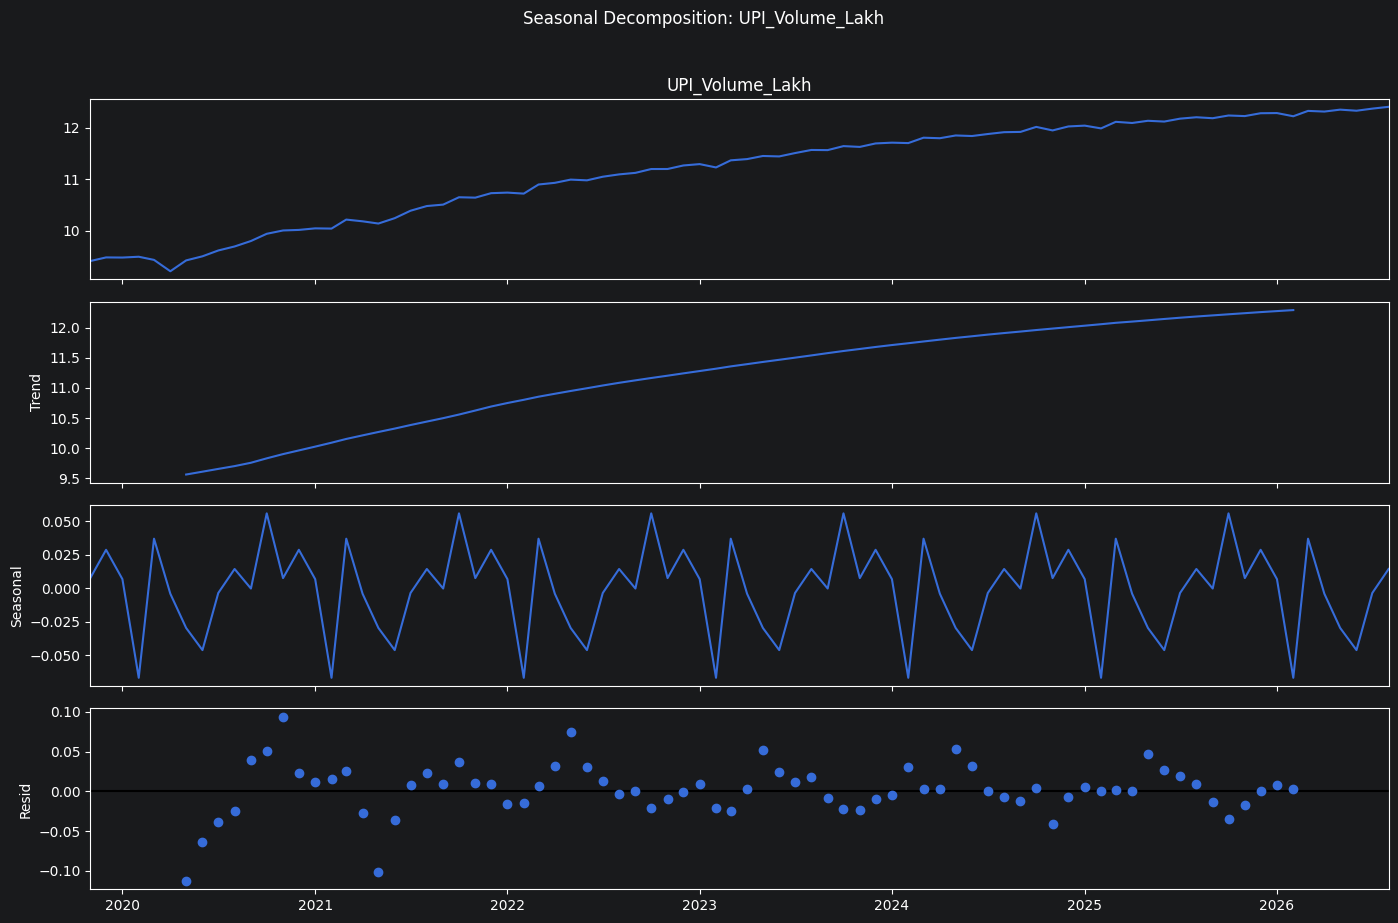

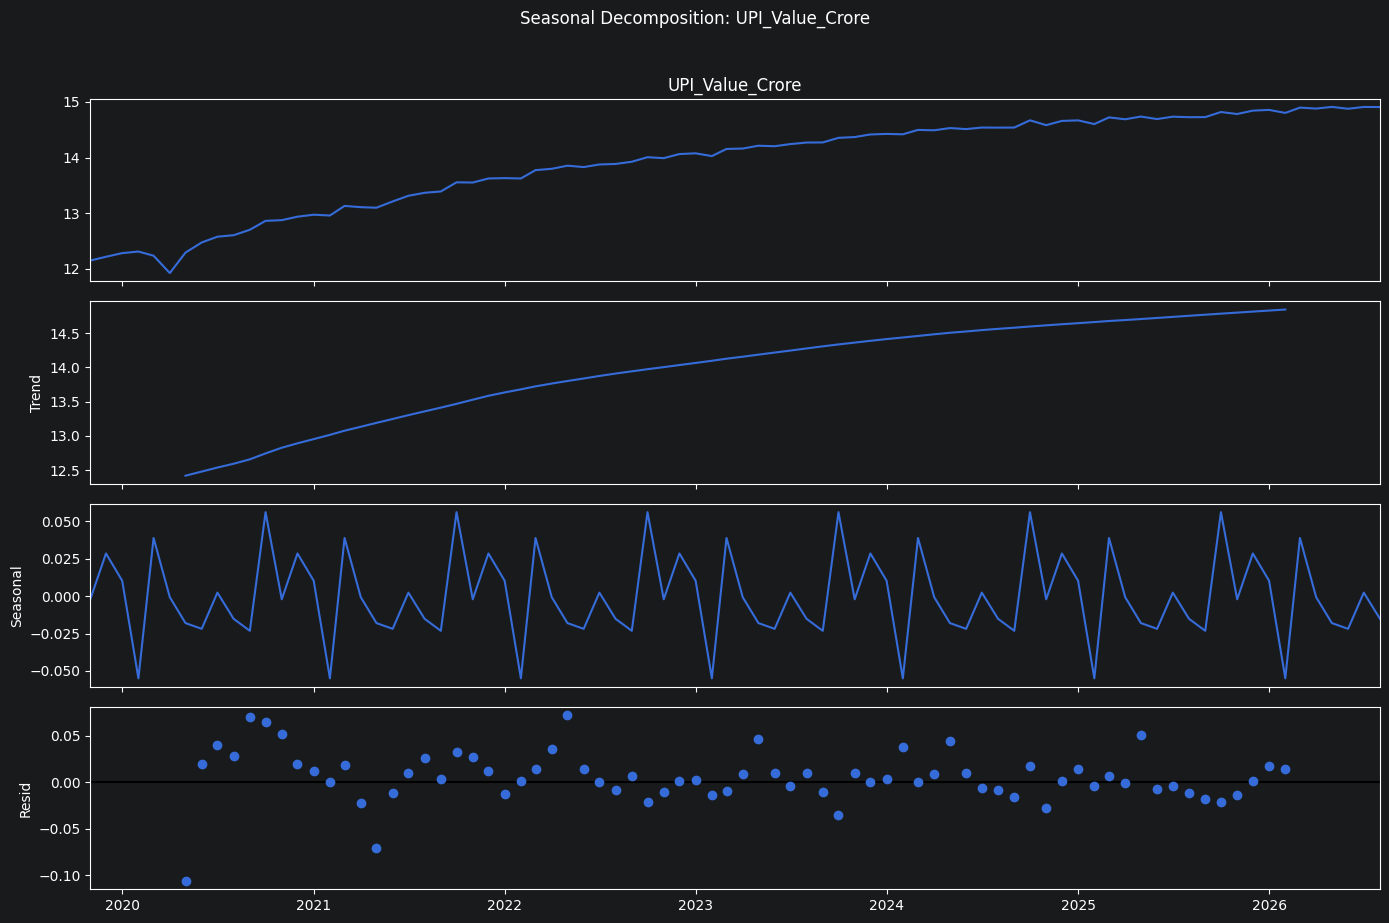

In [44]:
from statsmodels.tsa.seasonal import seasonal_decompose

upi_indicators = [
    "UPI_Volume_Lakh",
    "UPI_Value_Crore"
]

for col in upi_indicators:

    log_series = np.log1p(ts_df[col])

    decomposition = seasonal_decompose(
        log_series,
        model="additive",
        period=12
    )

    fig = decomposition.plot()
    fig.set_size_inches(14, 9)

    plt.suptitle(
        f"Seasonal Decomposition: {col}",
        y=1.02
    )

    plt.tight_layout()
    plt.show()

In [45]:
##Forecasting Model Development.

In [46]:
# Forecasting variables
forecast_columns = [
    "UPI_Volume_Lakh",
    "UPI_Value_Crore"
]

# Chronological train-test split
train = ts_df.iloc[:-12].copy()
test = ts_df.iloc[-12:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 70
Testing observations: 12

Training period:
2019-11-01 00:00:00 to 2025-08-01 00:00:00

Testing period:
2025-09-01 00:00:00 to 2026-08-01 00:00:00


In [47]:
##Establish baseline forecasting models

In [48]:
##Naïve forecast: Every future value equals the latest training observation.
##Seasonal naïve forecast: Each forecast equals the observation from the same month one year earlier.

In [49]:
baseline_results = {}

for col in forecast_columns:

    # Naive forecast
    naive_forecast = pd.Series(
        train[col].iloc[-1],
        index=test.index
    )

    # Seasonal naive forecast
    seasonal_forecast = pd.Series(
        train[col].iloc[-12:].values,
        index=test.index
    )

    baseline_results[col] = {
        "Naive": naive_forecast,
        "Seasonal_Naive": seasonal_forecast
    }

print("Baseline forecasts generated successfully.")

Baseline forecasts generated successfully.


In [50]:
#Evaluating baseline performance
#We will use MAE, RMSE and sMAPE.

In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

evaluation_results = []

for col in forecast_columns:

    actual = test[col]

    for model_name, forecast in baseline_results[col].items():

        mae = mean_absolute_error(actual, forecast)

        rmse = np.sqrt(mean_squared_error(actual, forecast))

        denominator = np.abs(actual) + np.abs(forecast)

        smape = np.mean(
            np.where(
                denominator == 0,
                0,
                200 * np.abs(actual - forecast) / denominator
            )
        )

        evaluation_results.append({
            "Indicator": col,
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "sMAPE_%": smape
        })

baseline_evaluation = pd.DataFrame(evaluation_results)

display(baseline_evaluation.round(2))

,Indicator,Model,MAE,RMSE,sMAPE_%
0,UPI_Volume_Lakh,Naive,20214.06,24153.67,9.43
1,UPI_Volume_Lakh,Seasonal_Naive,44935.21,45009.20,22.94
2,UPI_Value_Crore,Naive,337186.47,370777.82,12.54
3,UPI_Value_Crore,Seasonal_Naive,470778.66,471987.62,18.22


In [52]:
##The naïve model outperforms seasonal naïve on both indicators across all three error measures.

In [53]:
##Visualizing actual versus baseline forecasts

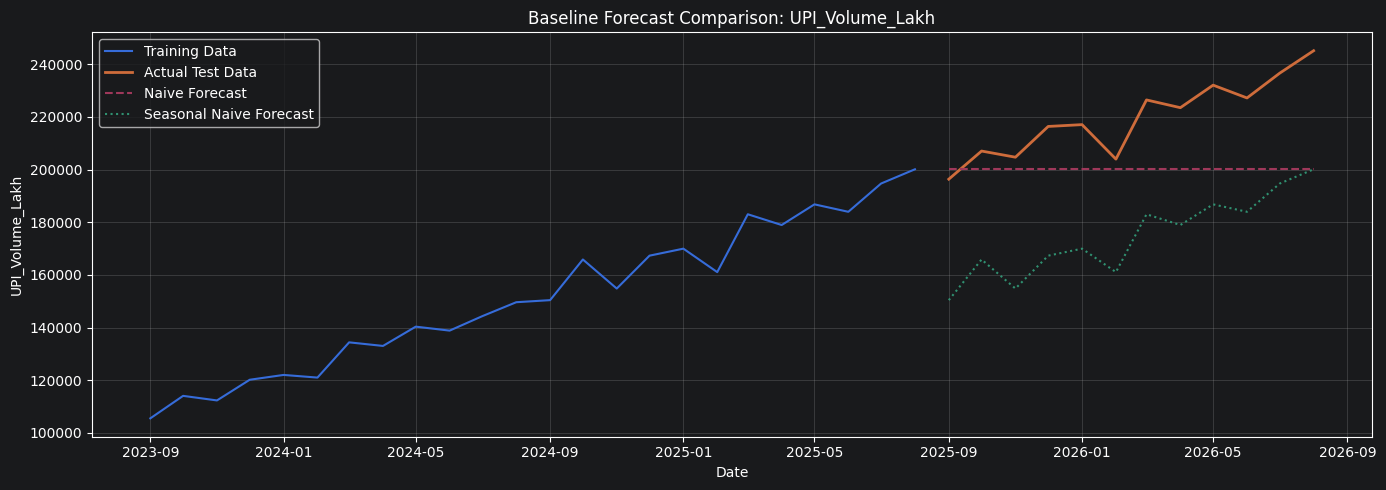

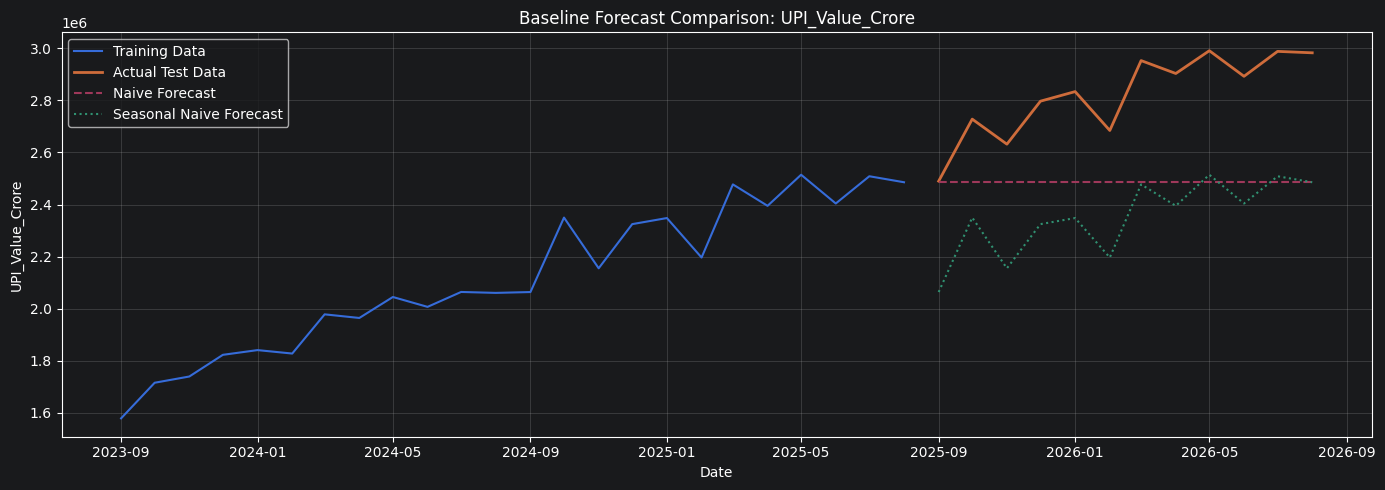

In [54]:
for col in forecast_columns:

    plt.figure(figsize=(14, 5))

    plt.plot(
        train.index[-24:],
        train[col].iloc[-24:],
        label="Training Data"
    )

    plt.plot(
        test.index,
        test[col],
        label="Actual Test Data",
        linewidth=2
    )

    plt.plot(
        test.index,
        baseline_results[col]["Naive"],
        label="Naive Forecast",
        linestyle="--"
    )

    plt.plot(
        test.index,
        baseline_results[col]["Seasonal_Naive"],
        label="Seasonal Naive Forecast",
        linestyle=":"
    )

    plt.title(f"Baseline Forecast Comparison: {col}")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [55]:
##What this means
#The latest observed value is a better baseline forecast than simply repeating the corresponding month from the previous year.
#The seasonal naïve model struggles because the series has a strong upward trajectory.
#Both naïve forecasts underestimate the actual values throughout much of the test period.

In [56]:
###Developing advanced forecasting models

In [57]:
## Holt's damped trend (ETS): Captures growth while allowing the trend to slow over time.
## ARIMA (1,1,1): Models changes in the series using autoregressive and moving-average components.

In [58]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import pandas as pd

model_forecasts = {}

for col in forecast_columns:

    # Log transformation
    train_log = np.log1p(train[col])

    # 1. Holt's damped trend
    ets_model = ExponentialSmoothing(
        train_log,
        trend="add",
        damped_trend=True,
        seasonal=None,
        initialization_method="estimated"
    )

    ets_fit = ets_model.fit(optimized=True)

    ets_forecast = np.expm1(
        ets_fit.forecast(len(test))
    )

    # 2. ARIMA (1,1,1)
    arima_model = ARIMA(
        train_log,
        order=(1, 1, 1)
    )

    arima_fit = arima_model.fit()

    arima_forecast = np.expm1(
        arima_fit.forecast(steps=len(test))
    )

    # Store forecasts
    model_forecasts[col] = {
        "Holt_Damped_Trend": pd.Series(
            np.maximum(ets_forecast, 0),
            index=test.index
        ),
        "ARIMA_111": pd.Series(
            np.maximum(arima_forecast, 0),
            index=test.index
        )
    }

print("ETS and ARIMA models fitted successfully.")

C:\Users\preet\PycharmProjects\WelcomeScreen\.venv\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\preet\PycharmProjects\WelcomeScreen\.venv\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


ETS and ARIMA models fitted successfully.


C:\Users\preet\PycharmProjects\WelcomeScreen\.venv\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\preet\PycharmProjects\WelcomeScreen\.venv\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


In [59]:
advanced_results = []

for col in forecast_columns:

    actual = test[col]

    for model_name, forecast in model_forecasts[col].items():

        mae = mean_absolute_error(actual, forecast)

        rmse = np.sqrt(
            mean_squared_error(actual, forecast)
        )

        denominator = np.abs(actual) + np.abs(forecast)

        smape = np.mean(
            np.where(
                denominator == 0,
                0,
                200 * np.abs(actual - forecast) / denominator
            )
        )

        advanced_results.append({
            "Indicator": col,
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "sMAPE_%": smape
        })

advanced_evaluation = pd.DataFrame(advanced_results)

display(advanced_evaluation.round(2))

,Indicator,Model,MAE,RMSE,sMAPE_%
0,UPI_Volume_Lakh,Holt_Damped_Trend,22417.55,25271.18,9.44
1,UPI_Volume_Lakh,ARIMA_111,35759.92,40802.35,14.46
2,UPI_Value_Crore,Holt_Damped_Trend,74925.44,82101.02,2.68
3,UPI_Value_Crore,ARIMA_111,337203.15,370792.99,12.54


In [60]:
##Naïve performs marginally better than Holt on all three metrics.
##The sMAPE difference between naïve and Holt is negligible.
##ARIMA performs substantially worse.
##The more sophisticated model does not provide an improvement for UPI volume.

In [61]:
all_evaluations = pd.concat(
    [
        baseline_evaluation,
        advanced_evaluation
    ],
    ignore_index=True
)

display(
    all_evaluations.sort_values(
        ["Indicator", "sMAPE_%"]
    ).round(2)
)

,Indicator,Model,MAE,RMSE,sMAPE_%
6,UPI_Value_Crore,Holt_Damped_Trend,74925.44,82101.02,2.68
2,UPI_Value_Crore,Naive,337186.47,370777.82,12.54
7,UPI_Value_Crore,ARIMA_111,337203.15,370792.99,12.54
3,UPI_Value_Crore,Seasonal_Naive,470778.66,471987.62,18.22
0,UPI_Volume_Lakh,Naive,20214.06,24153.67,9.43
4,UPI_Volume_Lakh,Holt_Damped_Trend,22417.55,25271.18,9.44
5,UPI_Volume_Lakh,ARIMA_111,35759.92,40802.35,14.46
1,UPI_Volume_Lakh,Seasonal_Naive,44935.21,45009.20,22.94


In [62]:
##Holt's damped trend performs substantially better than the other models for UPI transaction value.

##Its sMAPE is 2.68%, compared with 12.54% for the naïve model.

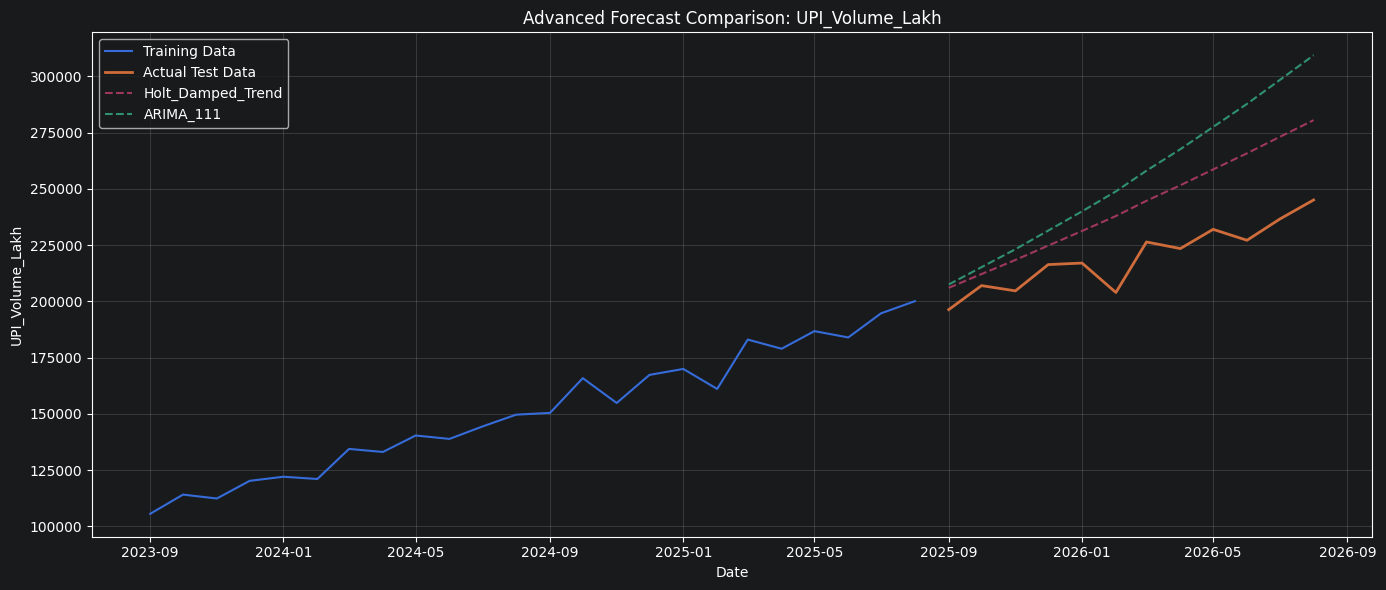

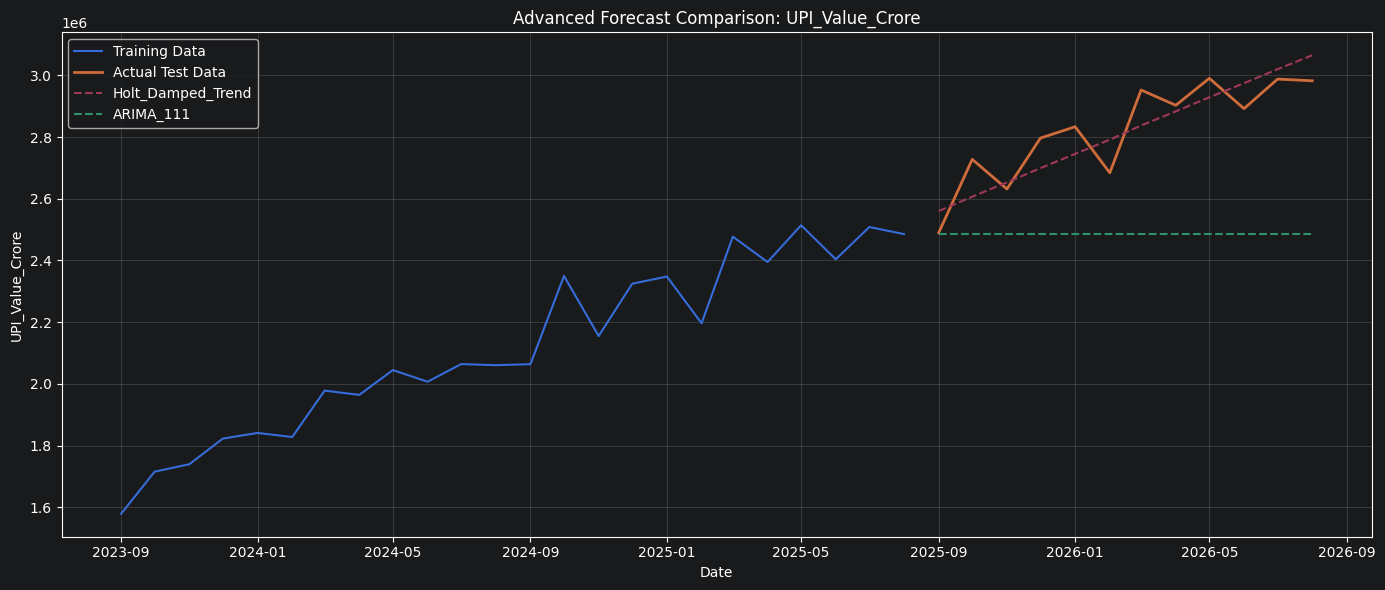

In [63]:
for col in forecast_columns:

    plt.figure(figsize=(14, 6))

    plt.plot(
        train.index[-24:],
        train[col].iloc[-24:],
        label="Training Data"
    )

    plt.plot(
        test.index,
        test[col],
        label="Actual Test Data",
        linewidth=2
    )

    for model_name, forecast in model_forecasts[col].items():

        plt.plot(
            test.index,
            forecast,
            linestyle="--",
            label=model_name
        )

    plt.title(f"Advanced Forecast Comparison: {col}")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [64]:
## Model Diagnostics and Validation

In [65]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

holt_models = {}

for col in forecast_columns:

    train_log = np.log1p(train[col])

    model = ExponentialSmoothing(
        train_log,
        trend="add",
        damped_trend=True,
        seasonal=None,
        initialization_method="estimated"
    )

    fitted = model.fit(optimized=True)

    holt_models[col] = fitted

    print("\nModel:", col)
    print(fitted.summary())


Model: UPI_Volume_Lakh
                       ExponentialSmoothing Model Results                       
Dep. Variable:          UPI_Volume_Lakh   No. Observations:                   70
Model:             ExponentialSmoothing   SSE                              0.297
Optimized:                         True   AIC                           -372.267
Trend:                         Additive   BIC                           -361.025
Seasonal:                          None   AICC                          -370.461
Seasonal Periods:                  None   Date:                 Tue, 03 Nov 2026
Box-Cox:                          False   Time:                         23:54:55
Box-Cox Coeff.:                    None                                         
                       coeff                 code              optimized      
------------------------------------------------------------------------------
smoothing_level            0.7621233                alpha                 True
smoothing_

In [66]:
##Examining Holt residuals

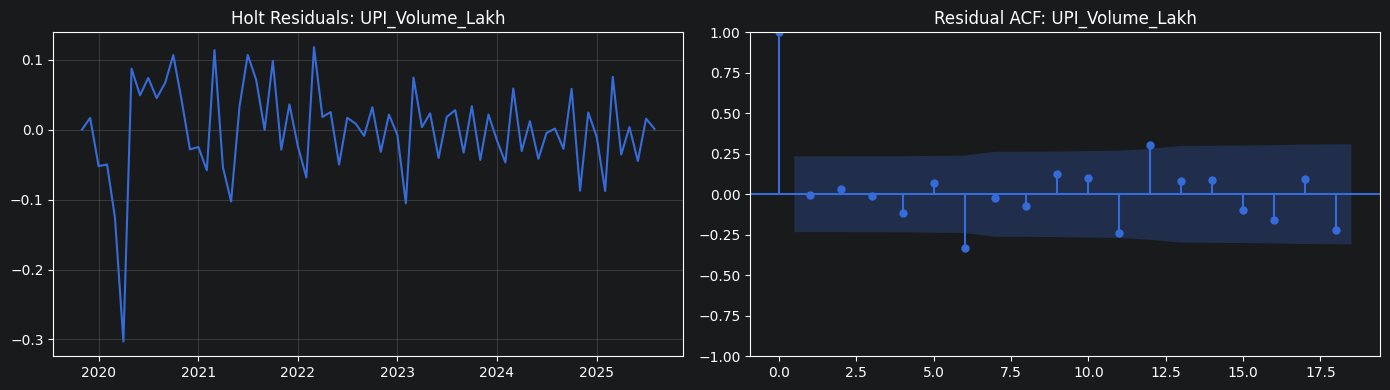

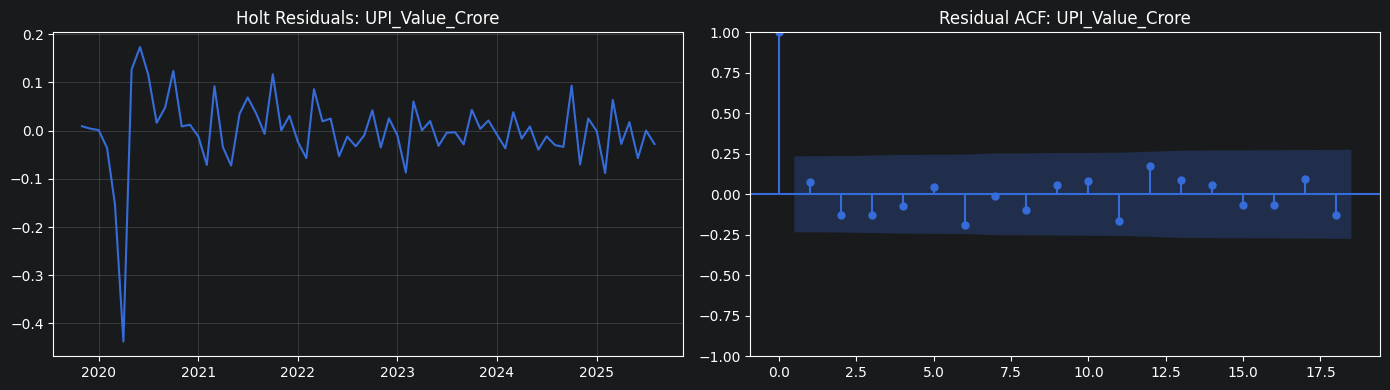

In [67]:
from statsmodels.graphics.tsaplots import plot_acf

for col in forecast_columns:

    residuals = holt_models[col].resid

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].plot(residuals)
    axes[0].set_title(f"Holt Residuals: {col}")
    axes[0].grid(alpha=0.3)

    plot_acf(
        residuals,
        lags=18,
        ax=axes[1]
    )

    axes[1].set_title(f"Residual ACF: {col}")

    plt.tight_layout()
    plt.show()

In [68]:
##Ljung–Box test for Holt residuals

In [69]:
from statsmodels.stats.diagnostic import acorr_ljungbox

for col in forecast_columns:

    residuals = holt_models[col].resid

    print("\nLjung-Box Test:", col)

    result = acorr_ljungbox(
        residuals,
        lags=[6, 12],
        return_df=True
    )

    display(result)


Ljung-Box Test: UPI_Volume_Lakh


,lb_stat,lb_pvalue
6,10.130674,0.119256
12,25.747847,0.011651



Ljung-Box Test: UPI_Value_Crore


,lb_stat,lb_pvalue
6,6.302495,0.390171
12,12.926187,0.374429


In [70]:
##rolling-origin validation

In [71]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

import numpy as np
import pandas as pd

validation_results = []

initial_window = 48
horizon = 6
step = 3

for col in forecast_columns:

    series = ts_df[col].dropna()

    for origin in range(
        initial_window,
        len(series) - horizon + 1,
        step
    ):

        train_fold = series.iloc[:origin]
        actual = series.iloc[origin:origin + horizon]

        # 1. Naive
        naive = np.repeat(
            train_fold.iloc[-1],
            horizon
        )

        # 2. Seasonal Naive
        seasonal_naive = np.tile(
            train_fold.iloc[-12:].values,
            int(np.ceil(horizon / 12))
        )[:horizon]

        # 3. Holt Damped Trend
        log_train = np.log1p(train_fold)

        ets = ExponentialSmoothing(
            log_train,
            trend="add",
            damped_trend=True,
            seasonal=None,
            initialization_method="estimated"
        ).fit(optimized=True)

        holt = np.maximum(
            np.expm1(ets.forecast(horizon).values),
            0
        )

        # 4. ARIMA
        arima = ARIMA(
            log_train,
            order=(1, 1, 1),
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit()

        arima_forecast = np.maximum(
            np.expm1(arima.forecast(horizon).values),
            0
        )

        forecasts = {
            "Naive": naive,
            "Seasonal_Naive": seasonal_naive,
            "Holt_Damped_Trend": holt,
            "ARIMA_111": arima_forecast
        }

        for model_name, forecast in forecasts.items():

            mae = np.mean(
                np.abs(actual.values - forecast)
            )

            rmse = np.sqrt(
                np.mean((actual.values - forecast) ** 2)
            )

            denominator = (
                np.abs(actual.values) + np.abs(forecast)
            )

            smape = np.mean(
                np.where(
                    denominator == 0,
                    0,
                    200 * np.abs(actual.values - forecast)
                    / denominator
                )
            )

            validation_results.append({
                "Indicator": col,
                "Origin": series.index[origin],
                "Model": model_name,
                "MAE": mae,
                "RMSE": rmse,
                "sMAPE_%": smape
            })

rolling_results = pd.DataFrame(validation_results)

print("Total validation forecasts:", len(rolling_results))

display(rolling_results.head(10))

Total validation forecasts: 80


,Indicator,Origin,Model,MAE,RMSE,sMAPE_%
0,UPI_Volume_Lakh,2023-11-01,Naive,10332.438333,12405.547003,8.511365
1,UPI_Volume_Lakh,2023-11-01,Seasonal_Naive,43464.376667,43557.711533,42.609439
2,UPI_Volume_Lakh,2023-11-01,Holt_Damped_Trend,7779.667635,8597.756604,6.034014
3,UPI_Volume_Lakh,2023-11-01,ARIMA_111,8154.149015,8918.869685,6.323450
4,UPI_Volume_Lakh,2024-02-01,Naive,13642.986667,15234.476941,10.455640
5,UPI_Volume_Lakh,2024-02-01,Seasonal_Naive,45731.761667,45745.798635,40.864362
6,UPI_Volume_Lakh,2024-02-01,Holt_Damped_Trend,6456.389929,7368.505952,4.606011
7,UPI_Volume_Lakh,2024-02-01,ARIMA_111,4738.234505,5352.650506,3.437465
8,UPI_Volume_Lakh,2024-05-01,Naive,15203.891667,17649.732576,10.623498
9,UPI_Volume_Lakh,2024-05-01,Seasonal_Naive,46135.506667,46210.055894,36.923894


In [72]:
##Summarise model performance

In [73]:
rolling_summary = (
    rolling_results
    .groupby(["Indicator", "Model"])
    .agg(
        Mean_MAE=("MAE", "mean"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_sMAPE=("sMAPE_%", "mean"),
        Validation_Folds=("Origin", "nunique")
    )
    .reset_index()
    .sort_values(["Indicator", "Mean_sMAPE"])
)

display(rolling_summary.round(2))

,Indicator,Model,Mean_MAE,Mean_RMSE,Mean_sMAPE,Validation_Folds
0,UPI_Value_Crore,ARIMA_111,81957.85,94729.85,3.40,10
1,UPI_Value_Crore,Holt_Damped_Trend,95956.69,112420.40,4.01,10
2,UPI_Value_Crore,Naive,131876.50,157271.33,5.78,10
3,UPI_Value_Crore,Seasonal_Naive,487986.20,489527.82,23.84,10
4,UPI_Volume_Lakh,ARIMA_111,7777.74,8854.22,4.36,10
5,UPI_Volume_Lakh,Holt_Damped_Trend,9699.19,10997.34,5.33,10
6,UPI_Volume_Lakh,Naive,12796.98,14531.56,7.74,10
7,UPI_Volume_Lakh,Seasonal_Naive,45651.95,45732.59,31.30,10


In [74]:
##Visualizing the comparison

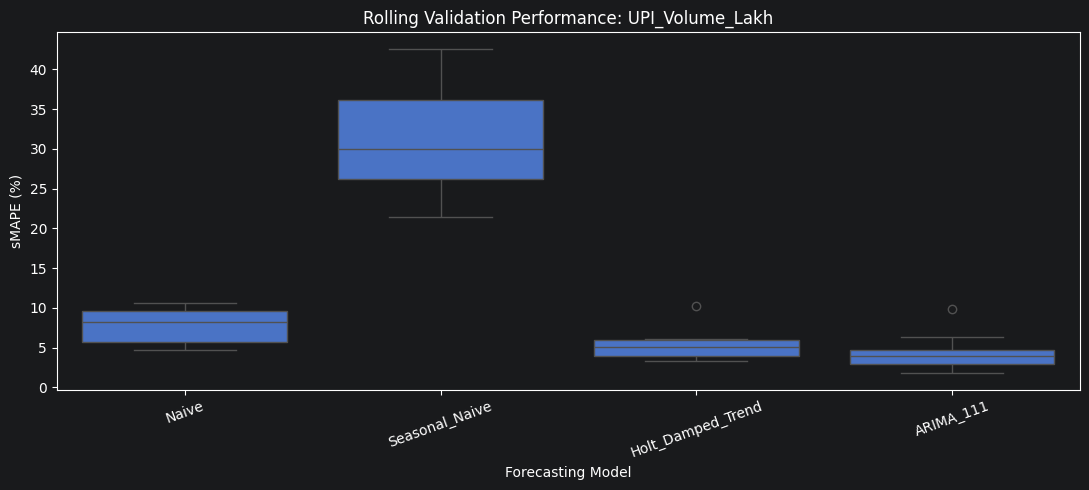

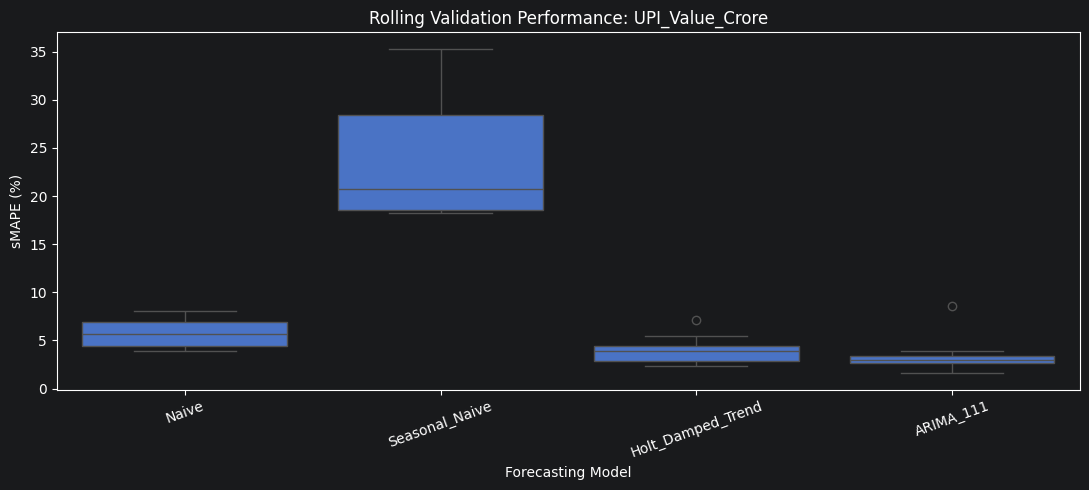

In [75]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in forecast_columns:

    subset = rolling_results[
        rolling_results["Indicator"] == col
    ]

    plt.figure(figsize=(11, 5))

    sns.boxplot(
        data=subset,
        x="Model",
        y="sMAPE_%"
    )

    plt.title(f"Rolling Validation Performance: {col}")
    plt.xlabel("Forecasting Model")
    plt.ylabel("sMAPE (%)")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

In [76]:
##ARIMA diagnostics

In [77]:
final_arima_models = {}

for col in forecast_columns:

    log_series = np.log1p(ts_df[col])

    model = ARIMA(
        log_series,
        order=(1, 1, 1),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit()

    final_arima_models[col] = fitted

    print("\n", "=" * 60)
    print("FINAL ARIMA MODEL:", col)
    print("=" * 60)

    print(fitted.summary())

    print("Convergence information:")
    print(fitted.mle_retvals)


FINAL ARIMA MODEL: UPI_Volume_Lakh
                               SARIMAX Results                                
Dep. Variable:        UPI_Volume_Lakh   No. Observations:                   82
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 102.169
Date:                Tue, 03 Nov 2026   AIC                           -198.338
Time:                        23:55:05   BIC                           -191.230
Sample:                    11-01-2019   HQIC                          -195.490
                         - 08-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9869      0.012     80.903      0.000       0.963       1.011
ma.L1         -1.0000    354.620     -0.003      0.998    -696.041     694.041
sigma2         0

In [78]:
##Residual Results

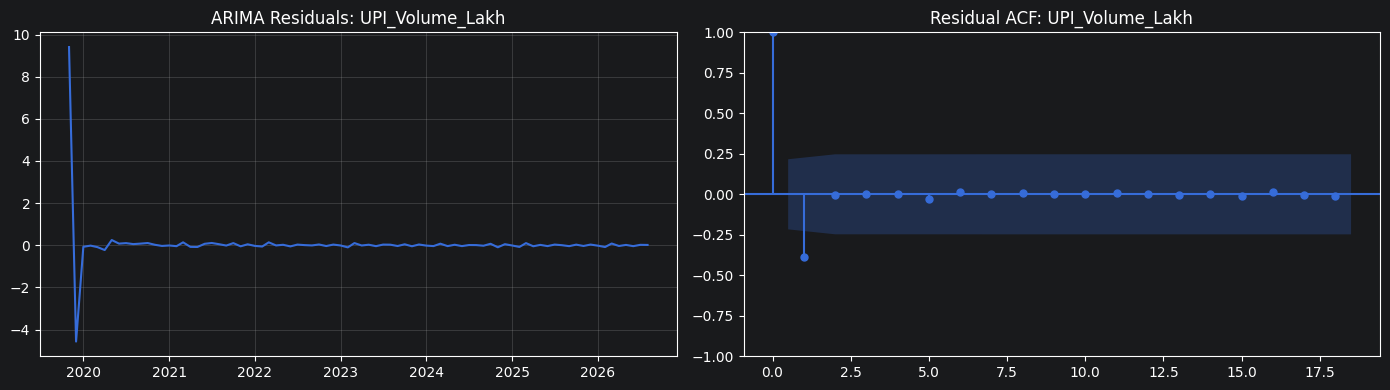

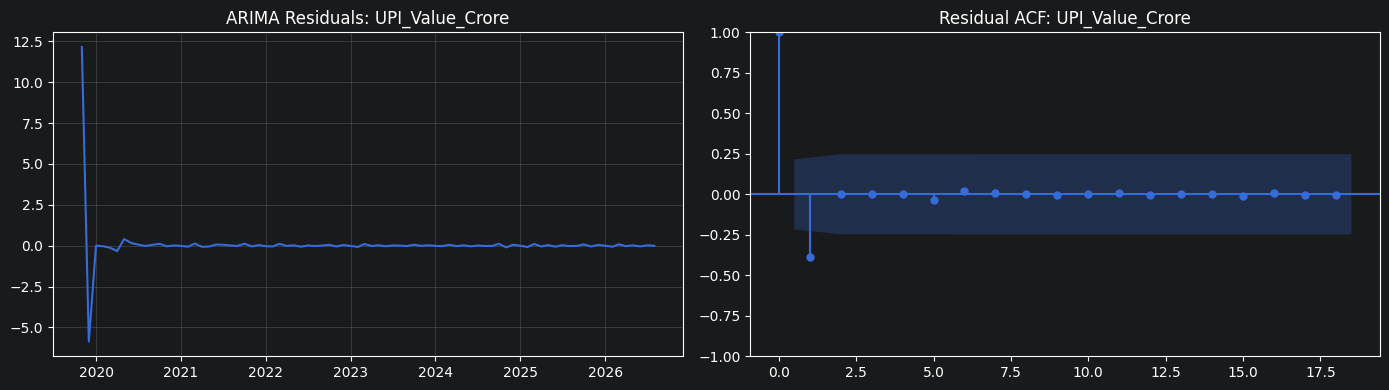

In [79]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

for col in forecast_columns:

    residuals = final_arima_models[col].resid

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].plot(residuals)
    axes[0].set_title(f"ARIMA Residuals: {col}")
    axes[0].grid(alpha=0.3)

    plot_acf(
        residuals,
        lags=18,
        ax=axes[1]
    )

    axes[1].set_title(f"Residual ACF: {col}")

    plt.tight_layout()
    plt.show()

In [80]:
##Ljung–Box tests

In [81]:
from statsmodels.stats.diagnostic import acorr_ljungbox

for col in forecast_columns:

    residuals = final_arima_models[col].resid

    print("\nLjung-Box Test:", col)

    result = acorr_ljungbox(
        residuals,
        lags=[6, 12],
        model_df=2,
        return_df=True
    )

    display(result)


Ljung-Box Test: UPI_Volume_Lakh


,lb_stat,lb_pvalue
6,12.928672,0.011630
12,12.937888,0.227165



Ljung-Box Test: UPI_Value_Crore


,lb_stat,lb_pvalue
6,13.072946,0.010925
12,13.088323,0.218775


In [82]:
##ARIMA model roots

In [83]:
for col in forecast_columns:

    fitted = final_arima_models[col]

    print("\nModel:", col)

    print("AR roots:", fitted.arroots)
    print("MA roots:", fitted.maroots)


Model: UPI_Volume_Lakh
AR roots: [1.01331235]
MA roots: [0.99998726]

Model: UPI_Value_Crore
AR roots: [1.02379641]
MA roots: [0.99999082]


In [84]:
##alternative model comparison

In [85]:
from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import pandas as pd
import warnings

candidate_orders = {
    "ARIMA_110": (1, 1, 0),
    "ARIMA_011": (0, 1, 1),
    "ARIMA_111": (1, 1, 1),
    "ARIMA_010_Drift": (0, 1, 0)
}

candidate_results = []

initial_window = 48
horizon = 6
step = 3

for col in forecast_columns:

    series = ts_df[col].dropna()

    for origin in range(
        initial_window,
        len(series) - horizon + 1,
        step
    ):

        train_fold = series.iloc[:origin]
        actual = series.iloc[origin:origin + horizon]

        log_train = np.log1p(train_fold)

        for model_name, order in candidate_orders.items():

            try:
                if model_name == "ARIMA_010_Drift":

                    model = ARIMA(
                        log_train,
                        order=order,
                        trend="t",
                        enforce_stationarity=True,
                        enforce_invertibility=True
                    )

                else:

                    model = ARIMA(
                        log_train,
                        order=order,
                        enforce_stationarity=True,
                        enforce_invertibility=True
                    )

                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    fitted = model.fit()

                forecast = np.maximum(
                    np.expm1(
                        fitted.forecast(steps=horizon).values
                    ),
                    0
                )

                mae = np.mean(
                    np.abs(actual.values - forecast)
                )

                rmse = np.sqrt(
                    np.mean((actual.values - forecast) ** 2)
                )

                denominator = (
                    np.abs(actual.values) + np.abs(forecast)
                )

                smape = np.mean(
                    np.where(
                        denominator == 0,
                        0,
                        200 * np.abs(actual.values - forecast)
                        / denominator
                    )
                )

                candidate_results.append({
                    "Indicator": col,
                    "Origin": series.index[origin],
                    "Model": model_name,
                    "MAE": mae,
                    "RMSE": rmse,
                    "sMAPE_%": smape,
                    "Converged": fitted.mle_retvals.get(
                        "converged", True
                    )
                })

            except Exception as error:

                print(
                    f"Failed: {col}, {model_name}, "
                    f"origin {origin}: {error}"
                )

candidate_validation = pd.DataFrame(candidate_results)

In [86]:
candidate_summary = (
    candidate_validation
    .groupby(["Indicator", "Model"])
    .agg(
        Mean_MAE=("MAE", "mean"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_sMAPE=("sMAPE_%", "mean"),
        Successful_Folds=("Origin", "nunique"),
        Convergence_Rate=("Converged", "mean")
    )
    .reset_index()
    .sort_values(["Indicator", "Mean_sMAPE"])
)

display(candidate_summary.round(3))

,Indicator,Model,Mean_MAE,Mean_RMSE,Mean_sMAPE,Successful_Folds,Convergence_Rate
2,UPI_Value_Crore,ARIMA_110,131392.663,156756.959,5.736,10,1.0
1,UPI_Value_Crore,ARIMA_011,131580.646,156925.927,5.748,10,1.0
3,UPI_Value_Crore,ARIMA_111,177976.884,200432.394,7.318,10,1.0
0,UPI_Value_Crore,ARIMA_010_Drift,254618.708,283466.123,9.935,10,1.0
7,UPI_Volume_Lakh,ARIMA_111,13140.017,14743.690,7.023,10,0.9
6,UPI_Volume_Lakh,ARIMA_110,12363.837,14051.083,7.451,10,1.0
5,UPI_Volume_Lakh,ARIMA_011,12574.985,14287.311,7.595,10,1.0
4,UPI_Volume_Lakh,ARIMA_010_Drift,15772.910,17692.917,8.253,10,1.0


In [87]:
full_sample_models = {}

for col in forecast_columns:

    log_series = np.log1p(ts_df[col])

    for model_name, order in candidate_orders.items():

        if model_name == "ARIMA_010_Drift":

            model = ARIMA(
                log_series,
                order=order,
                trend="t",
                enforce_stationarity=True,
                enforce_invertibility=True
            )

        else:

            model = ARIMA(
                log_series,
                order=order,
                enforce_stationarity=True,
                enforce_invertibility=True
            )

        fitted = model.fit()

        full_sample_models[(col, model_name)] = fitted

        print("\n", col, model_name)

        print("Converged:", fitted.mle_retvals.get(
            "converged", True
        ))

        print("AIC:", fitted.aic)
        print("AR roots:", fitted.arroots)
        print("MA roots:", fitted.maroots)


 UPI_Volume_Lakh ARIMA_110
Converged: True
AIC: -185.54107959484892
AR roots: [15.74607761]
MA roots: []

 UPI_Volume_Lakh ARIMA_011
Converged: True
AIC: -185.42469601467255
AR roots: []
MA roots: [-24.33841944]

 UPI_Volume_Lakh ARIMA_111
Converged: True
AIC: -201.89384619605934
AR roots: [1.00223211]
MA roots: [1.03782505]

 UPI_Volume_Lakh ARIMA_010_Drift
Converged: True
AIC: -207.70329645988886
AR roots: []
MA roots: []


C:\Users\preet\PycharmProjects\WelcomeScreen\.venv\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\preet\PycharmProjects\WelcomeScreen\.venv\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'



 UPI_Value_Crore ARIMA_110
Converged: True
AIC: -164.4221488786895
AR roots: [-41.79563694]
MA roots: []

 UPI_Value_Crore ARIMA_011
Converged: True
AIC: -164.41397283540144
AR roots: []
MA roots: [51.13948464]


C:\Users\preet\PycharmProjects\WelcomeScreen\.venv\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\preet\PycharmProjects\WelcomeScreen\.venv\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'



 UPI_Value_Crore ARIMA_111
Converged: True
AIC: -162.5044571594481
AR roots: [-3.11614414]
MA roots: [-3.52895109]

 UPI_Value_Crore ARIMA_010_Drift
Converged: True
AIC: -178.32890918845385
AR roots: []
MA roots: []


In [88]:
## Candidate model selection

In [89]:
#ARIMA (1,1,0)
#It has the lowest error across all three metrics, with 100% convergence.

In [90]:
##Final model diagnostics

In [91]:
from statsmodels.tsa.arima.model import ARIMA

final_models = {}

for col in forecast_columns:

    log_series = np.log1p(ts_df[col])

    model = ARIMA(
        log_series,
        order=(1, 1, 0),
        enforce_stationarity=True,
        enforce_invertibility=True
    )

    fitted = model.fit()

    final_models[col] = fitted

    print("\n", "=" * 60)
    print("SELECTED MODEL:", col)
    print("=" * 60)

    print(fitted.summary())

    print("\nConverged:",
          fitted.mle_retvals.get("converged", True))

    print("AR roots:", fitted.arroots)


SELECTED MODEL: UPI_Volume_Lakh
                               SARIMAX Results                                
Dep. Variable:        UPI_Volume_Lakh   No. Observations:                   82
Model:                 ARIMA(1, 1, 0)   Log Likelihood                  94.771
Date:                Tue, 03 Nov 2026   AIC                           -185.541
Time:                        23:55:20   BIC                           -180.752
Sample:                    11-01-2019   HQIC                          -183.620
                         - 08-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0635      0.091      0.696      0.487      -0.115       0.242
sigma2         0.0056      0.001      7.241      0.000       0.004       0.007
Ljung-Box (L1) (Q):

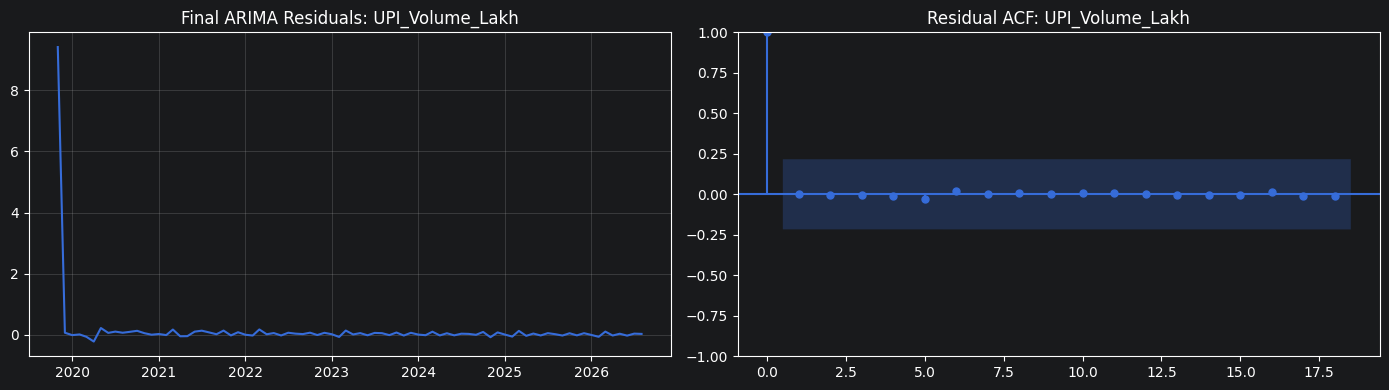

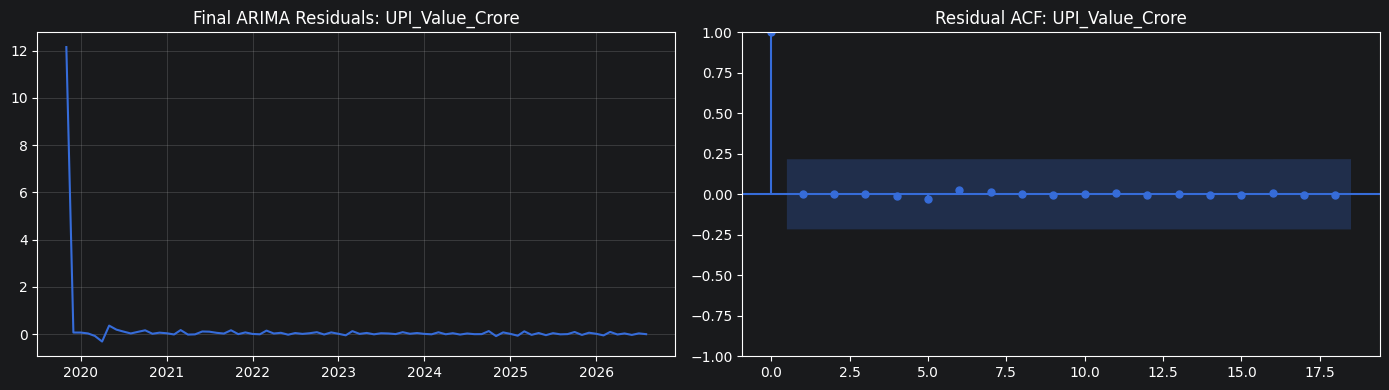

In [92]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

for col in forecast_columns:

    residuals = final_models[col].resid

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].plot(residuals)
    axes[0].set_title(f"Final ARIMA Residuals: {col}")
    axes[0].grid(alpha=0.3)

    plot_acf(
        residuals,
        lags=18,
        ax=axes[1]
    )

    axes[1].set_title(f"Residual ACF: {col}")

    plt.tight_layout()
    plt.show()

In [93]:
from statsmodels.stats.diagnostic import acorr_ljungbox

for col in forecast_columns:

    residuals = final_models[col].resid

    print("\nLjung-Box Test:", col)

    result = acorr_ljungbox(
        residuals,
        lags=[6, 12],
        model_df=1,
        return_df=True
    )

    display(result)


Ljung-Box Test: UPI_Volume_Lakh


,lb_stat,lb_pvalue
6,0.108467,0.999802
12,0.122201,1.000000



Ljung-Box Test: UPI_Value_Crore


,lb_stat,lb_pvalue
6,0.142619,0.999612
12,0.166751,1.000000


In [94]:
from statsmodels.stats.diagnostic import het_arch
from scipy.stats import jarque_bera

for col in forecast_columns:

    residuals = final_models[col].resid

    print("\nDiagnostics:", col)

    jb_stat, jb_pvalue = jarque_bera(residuals)

    arch_stat, arch_pvalue, _, _ = het_arch(
        residuals,
        nlags=6
    )

    print("Jarque-Bera p-value:", jb_pvalue)
    print("ARCH test p-value:", arch_pvalue)


Diagnostics: UPI_Volume_Lakh
Jarque-Bera p-value: 0.0
ARCH test p-value: 2.6115167699574027e-06

Diagnostics: UPI_Value_Crore
Jarque-Bera p-value: 0.0
ARCH test p-value: 4.175096936359755e-12


In [95]:
##re-running results due to inconsistency in the output:
# The UPI volume model summary reports Ljung–Box Q = 6.99 and p = 0.01 at lag 1.
# Ljung–Box test reports a statistic of 0.108 at lag 6 and p = 0.9998.
# The cumulative Ljung–Box statistic at lag 6 cannot be smaller than the statistic at lag 1 when calculated on the same residual series.

In [96]:
for col in forecast_columns:

    residuals = final_models[col].resid

    print("\nIndicator:", col)

    result = acorr_ljungbox(
        residuals,
        lags=[1, 6, 12],
        model_df=1,
        return_df=True
    )

    print(result.to_string())


Indicator: UPI_Volume_Lakh
     lb_stat  lb_pvalue
1   0.000556        NaN
6   0.108467   0.999802
12  0.122201   1.000000

Indicator: UPI_Value_Crore
     lb_stat  lb_pvalue
1   0.000309        NaN
6   0.142619   0.999612
12  0.166751   1.000000


In [97]:
simple_results = []

candidate_models = {
    "Random_Walk": {
        "order": (0, 1, 0),
        "trend": "n"
    },
    "Random_Walk_Drift": {
        "order": (0, 1, 0),
        "trend": "t"
    },
    "ARIMA_110": {
        "order": (1, 1, 0),
        "trend": "n"
    }
}

initial_window = 48
horizon = 6
step = 3

for col in forecast_columns:

    series = ts_df[col].dropna()

    for origin in range(
        initial_window,
        len(series) - horizon + 1,
        step
    ):

        train_fold = series.iloc[:origin]
        actual = series.iloc[origin:origin + horizon]

        log_train = np.log1p(train_fold)

        for name, config in candidate_models.items():

            model = ARIMA(
                log_train,
                order=config["order"],
                trend=config["trend"],
                enforce_stationarity=True,
                enforce_invertibility=True
            )

            fitted = model.fit()

            forecast = np.maximum(
                np.expm1(
                    fitted.forecast(horizon).values
                ),
                0
            )

            mae = np.mean(
                np.abs(actual.values - forecast)
            )

            rmse = np.sqrt(
                np.mean(
                    (actual.values - forecast) ** 2
                )
            )

            denominator = (
                np.abs(actual.values) + np.abs(forecast)
            )

            smape = np.mean(
                np.where(
                    denominator == 0,
                    0,
                    200 * np.abs(actual.values - forecast)
                    / denominator
                )
            )

            simple_results.append({
                "Indicator": col,
                "Origin": series.index[origin],
                "Model": name,
                "MAE": mae,
                "RMSE": rmse,
                "sMAPE_%": smape,
                "Converged": fitted.mle_retvals.get(
                    "converged", True
                )
            })

simple_validation = pd.DataFrame(simple_results)

C:\Users\preet\PycharmProjects\WelcomeScreen\.venv\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\preet\PycharmProjects\WelcomeScreen\.venv\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\preet\PycharmProjects\WelcomeScreen\.venv\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\preet\PycharmProjects\WelcomeScreen\.venv\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed t

In [98]:
# Count successful and unsuccessful model fits

convergence_check = (
    simple_validation
    .groupby(["Indicator", "Model"])
    .agg(
        Total_Folds=("Converged", "size"),
        Successful_Fits=("Converged", "sum"),
        Failed_Fits=("Converged", lambda x: (~x).sum()),
        Convergence_Rate=("Converged", "mean")
    )
    .reset_index()
)

convergence_check["Convergence_Rate"] *= 100

display(convergence_check.round(2))

,Indicator,Model,Total_Folds,Successful_Fits,Failed_Fits,Convergence_Rate
0,UPI_Value_Crore,ARIMA_110,10,10,0,100.0
1,UPI_Value_Crore,Random_Walk,10,7,3,70.0
2,UPI_Value_Crore,Random_Walk_Drift,10,10,0,100.0
3,UPI_Volume_Lakh,ARIMA_110,10,10,0,100.0
4,UPI_Volume_Lakh,Random_Walk,10,8,2,80.0
5,UPI_Volume_Lakh,Random_Walk_Drift,10,10,0,100.0


In [99]:
fitted = model.fit()

In [100]:
fitted = model.fit(
    method="statespace",
    method_kwargs={
        "maxiter": 500,
        "disp": False
    }
)

In [101]:
converged = fitted.mle_retvals.get("converged", False)

In [102]:
simple_summary = (
    simple_validation
    .groupby(["Indicator", "Model"])
    .agg(
        Mean_MAE=("MAE", "mean"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_sMAPE=("sMAPE_%", "mean"),
        Successful_Folds=("Origin", "nunique"),
        Convergence_Rate=("Converged", "mean")
    )
    .reset_index()
    .sort_values(["Indicator", "Mean_sMAPE"])
)

display(simple_summary.round(3))

,Indicator,Model,Mean_MAE,Mean_RMSE,Mean_sMAPE,Successful_Folds,Convergence_Rate
0,UPI_Value_Crore,ARIMA_110,131392.663,156756.959,5.736,10,1.0
1,UPI_Value_Crore,Random_Walk,131876.498,157271.327,5.775,10,0.7
2,UPI_Value_Crore,Random_Walk_Drift,254618.708,283466.123,9.935,10,1.0
3,UPI_Volume_Lakh,ARIMA_110,12363.837,14051.083,7.451,10,1.0
4,UPI_Volume_Lakh,Random_Walk,12796.984,14531.564,7.744,10,0.8
5,UPI_Volume_Lakh,Random_Walk_Drift,15772.910,17692.917,8.253,10,1.0


In [103]:
for col in forecast_columns:

    fitted = final_models[col]

    burn = fitted.loglikelihood_burn

    residuals = fitted.resid[burn:]

    print("\nLjung-Box Test:", col)
    print("Observations excluded:", burn)

    result = acorr_ljungbox(
        residuals,
        lags=[6, 12],
        model_df=1,
        return_df=True
    )

    display(result)


Ljung-Box Test: UPI_Volume_Lakh
Observations excluded: 1


,lb_stat,lb_pvalue
6,24.410484,1.810198e-04
12,61.476966,4.923748e-09



Ljung-Box Test: UPI_Value_Crore
Observations excluded: 1


,lb_stat,lb_pvalue
6,11.278094,0.046137
12,33.089095,0.000509


In [104]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
import pandas as pd

seasonal_candidates = {
    "ARIMA_110": {
        "order": (1, 1, 0),
        "seasonal_order": (0, 0, 0, 0)
    },

    "SARIMA_010_100_12": {
        "order": (0, 1, 0),
        "seasonal_order": (1, 0, 0, 12)
    },

    "SARIMA_110_100_12": {
        "order": (1, 1, 0),
        "seasonal_order": (1, 0, 0, 12)
    }
}

seasonal_results = []

initial_window = 48
horizon = 6
step = 3

for col in forecast_columns:

    series = ts_df[col].dropna()

    for origin in range(
        initial_window,
        len(series) - horizon + 1,
        step
    ):

        train = series.iloc[:origin]
        actual = series.iloc[origin:origin + horizon]

        log_train = np.log1p(train)

        for name, config in seasonal_candidates.items():

            try:
                model = SARIMAX(
                    log_train,
                    order=config["order"],
                    seasonal_order=config["seasonal_order"],
                    trend="n",
                    enforce_stationarity=True,
                    enforce_invertibility=True
                )

                fitted = model.fit(
                    maxiter=500,
                    disp=False
                )

                converged = fitted.mle_retvals.get(
                    "converged", False
                )

                if not converged:
                    continue

                forecast = np.maximum(
                    np.expm1(
                        fitted.forecast(horizon).values
                    ),
                    0
                )

                actual_values = actual.values

                mae = np.mean(
                    np.abs(actual_values - forecast)
                )

                rmse = np.sqrt(
                    np.mean(
                        (actual_values - forecast) ** 2
                    )
                )

                denominator = (
                    np.abs(actual_values) + np.abs(forecast)
                )

                smape = np.mean(
                    np.where(
                        denominator == 0,
                        0,
                        200 * np.abs(actual_values - forecast)
                        / denominator
                    )
                )

                seasonal_results.append({
                    "Indicator": col,
                    "Model": name,
                    "Origin": origin,
                    "MAE": mae,
                    "RMSE": rmse,
                    "sMAPE_%": smape,
                    "Converged": converged
                })

            except Exception as e:
                print(
                    f"Failed: {col} | {name} | "
                    f"Origin {origin} | {e}"
                )

In [105]:
seasonal_validation = pd.DataFrame(seasonal_results)

seasonal_summary = (
    seasonal_validation
    .groupby(["Indicator", "Model"])
    .agg(
        Mean_MAE=("MAE", "mean"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_sMAPE=("sMAPE_%", "mean"),
        Successful_Folds=("Converged", "sum")
    )
    .reset_index()
    .sort_values(
        ["Indicator", "Mean_sMAPE"]
    )
)

display(seasonal_summary.round(3))

,Indicator,Model,Mean_MAE,Mean_RMSE,Mean_sMAPE,Successful_Folds
2,UPI_Value_Crore,SARIMA_110_100_12,64082.321,73940.071,2.757,10
1,UPI_Value_Crore,SARIMA_010_100_12,64382.914,74203.587,2.770,10
0,UPI_Value_Crore,ARIMA_110,131392.663,156756.959,5.736,10
4,UPI_Volume_Lakh,SARIMA_010_100_12,3713.655,4588.367,2.248,10
5,UPI_Volume_Lakh,SARIMA_110_100_12,3752.569,4616.329,2.274,10
3,UPI_Volume_Lakh,ARIMA_110,12363.837,14051.083,7.451,10


In [106]:
###Final seasonal model diagnostics

In [107]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

selected_configs = {
    "UPI_Volume_Lakh": {
        "order": (0, 1, 0),
        "seasonal_order": (1, 0, 0, 12)
    },
    "UPI_Value_Crore": {
        "order": (1, 1, 0),
        "seasonal_order": (1, 0, 0, 12)
    }
}

final_seasonal_models = {}

for col, config in selected_configs.items():

    log_series = np.log1p(ts_df[col])

    model = SARIMAX(
        log_series,
        order=config["order"],
        seasonal_order=config["seasonal_order"],
        trend="n",
        enforce_stationarity=True,
        enforce_invertibility=True
    )

    fitted = model.fit(
        maxiter=500,
        disp=False
    )

    final_seasonal_models[col] = fitted

    print("\n", "=" * 60)
    print("FINAL SEASONAL MODEL:", col)
    print("=" * 60)

    print(fitted.summary())

    print(
        "Converged:",
        fitted.mle_retvals.get("converged", False)
    )

    print("AR roots:", fitted.arroots)
print("AR roots:", fitted.arroots)
print("MA roots:", fitted.maroots)

print("Converged:",
      fitted.mle_retvals.get("converged", False))

print("AIC:", fitted.aic)
print("BIC:", fitted.bic)


FINAL SEASONAL MODEL: UPI_Volume_Lakh
                                     SARIMAX Results                                      
Dep. Variable:                    UPI_Volume_Lakh   No. Observations:                   82
Model:             SARIMAX(0, 1, 0)x(1, 0, 0, 12)   Log Likelihood                 114.237
Date:                            Tue, 03 Nov 2026   AIC                           -224.474
Time:                                    23:55:41   BIC                           -219.685
Sample:                                11-01-2019   HQIC                          -222.553
                                     - 08-01-2026                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.S.L12       0.6971      0.047     14.872      0.000       0.605       0.

In [108]:
for col, fitted in final_seasonal_models.items():

    print("\n" + "=" * 60)
    print("MODEL:", col)
    print("=" * 60)

    print(fitted.summary())

    print("\nConvergence:", fitted.mle_retvals)
    print("AR roots:", fitted.arroots)
    print("MA roots:", fitted.maroots)


MODEL: UPI_Volume_Lakh
                                     SARIMAX Results                                      
Dep. Variable:                    UPI_Volume_Lakh   No. Observations:                   82
Model:             SARIMAX(0, 1, 0)x(1, 0, 0, 12)   Log Likelihood                 114.237
Date:                            Tue, 03 Nov 2026   AIC                           -224.474
Time:                                    23:55:41   BIC                           -219.685
Sample:                                11-01-2019   HQIC                          -222.553
                                     - 08-01-2026                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.S.L12       0.6971      0.047     14.872      0.000       0.605       0.789
sigma2     

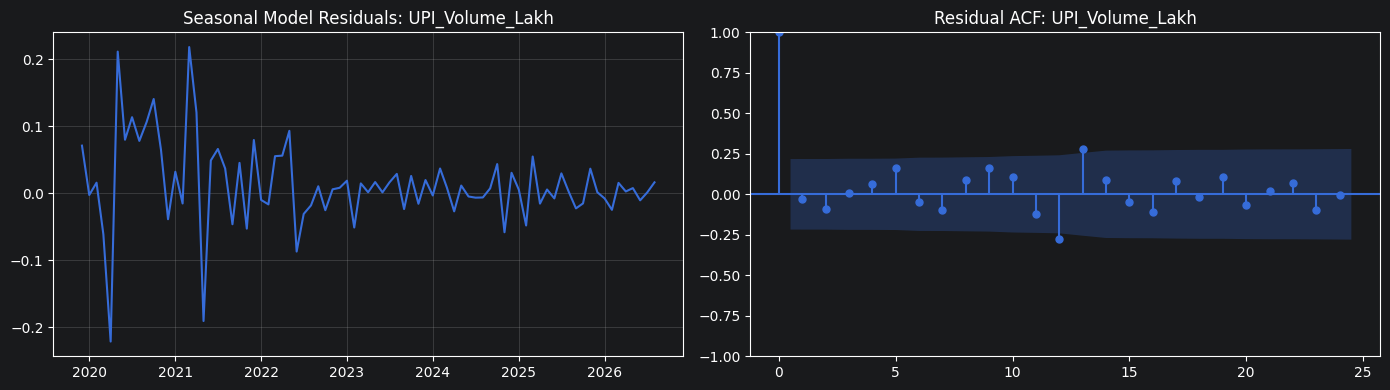

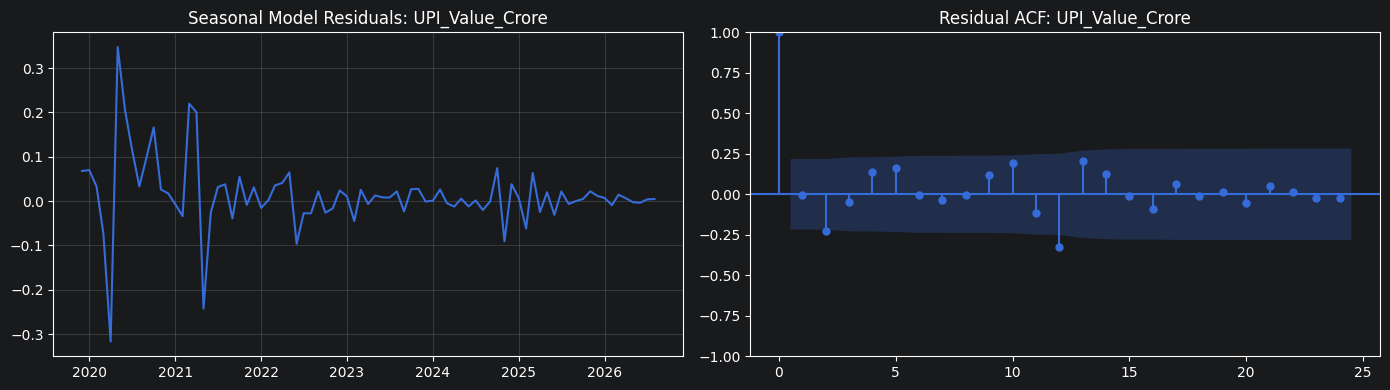

In [109]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

for col, fitted in final_seasonal_models.items():

    burn = fitted.loglikelihood_burn
    residuals = fitted.resid[burn:]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].plot(residuals)
    axes[0].set_title(f"Seasonal Model Residuals: {col}")
    axes[0].grid(alpha=0.3)

    plot_acf(
        residuals,
        lags=24,
        ax=axes[1]
    )

    axes[1].set_title(f"Residual ACF: {col}")

    plt.tight_layout()
    plt.show()

In [110]:
from statsmodels.stats.diagnostic import acorr_ljungbox

for col, fitted in final_seasonal_models.items():

    burn = fitted.loglikelihood_burn
    residuals = fitted.resid[burn:]

    # Count estimated AR and MA terms for degrees of freedom
    config = selected_configs[col]

    model_df = (
        config["order"][0]
        + config["order"][2]
        + config["seasonal_order"][0]
        + config["seasonal_order"][2]
    )

    print("\nLjung-Box Test:", col)

    result = acorr_ljungbox(
        residuals,
        lags=[6, 12, 18, 24],
        model_df=model_df,
        return_df=True
    )

    display(result)


Ljung-Box Test: UPI_Volume_Lakh


,lb_stat,lb_pvalue
6,3.639018,0.602465
12,17.743691,0.087722
18,28.365625,0.040843
24,31.785490,0.104687



Ljung-Box Test: UPI_Value_Crore


,lb_stat,lb_pvalue
6,8.460708,0.076087
12,24.757119,0.005825
18,31.783564,0.010669
24,32.553984,0.068430


In [111]:
from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import het_arch

for col, fitted in final_seasonal_models.items():

    residuals = fitted.resid[
        fitted.loglikelihood_burn:
    ]

    jb = jarque_bera(residuals)

    arch = het_arch(
        residuals,
        nlags=6
    )

    print("\nDiagnostics:", col)

    print("Jarque-Bera p-value:", jb.pvalue)
    print("ARCH test p-value:", arch[1])


Diagnostics: UPI_Volume_Lakh
Jarque-Bera p-value: 1.2946755920007693e-12
ARCH test p-value: 0.000612802215329316

Diagnostics: UPI_Value_Crore
Jarque-Bera p-value: 5.150569088127671e-36
ARCH test p-value: 3.3140849714733622e-06


In [112]:
#12-month forecasts and prediction intervals

In [113]:
import numpy as np
import pandas as pd

forecast_results = {}

forecast_dates = pd.date_range(
    start=ts_df.index[-1] + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

for col, fitted in final_seasonal_models.items():

    # Generate forecast on log-transformed scale
    forecast = fitted.get_forecast(steps=12)

    # Forecast mean and 95% prediction interval
    mean_log = forecast.predicted_mean
    conf_int_log = forecast.conf_int(alpha=0.05)

    # Convert back to original scale
    forecast_mean = np.expm1(mean_log)
    lower_95 = np.expm1(conf_int_log.iloc[:, 0])
    upper_95 = np.expm1(conf_int_log.iloc[:, 1])

    # Prevent negative transaction forecasts
    lower_95 = lower_95.clip(lower=0)
    forecast_mean = forecast_mean.clip(lower=0)

    forecast_df = pd.DataFrame({
        "Date": forecast_dates,
        "Forecast": forecast_mean.values,
        "Lower_95": lower_95.values,
        "Upper_95": upper_95.values
    })

    forecast_results[col] = forecast_df

    print(f"\n{col} — 12-Month Forecast")
    display(forecast_df.round(2))


UPI_Volume_Lakh — 12-Month Forecast


,Date,Forecast,Lower_95,Upper_95
0,2026-09-01,241879.23,216646.92,270050.27
1,2026-10-01,250973.45,214764.87,293286.64
2,2026-11-01,248992.83,205738.25,301341.25
3,2026-12-01,258812.37,207631.34,322609.43
4,2027-01-01,259385.66,202749.09,331843.18
5,2027-02-01,248375.13,189631.14,325316.77
6,2027-03-01,267147.67,199600.96,357552.66
7,2027-04-01,264722.02,193847.84,361508.91
8,2027-05-01,271743.57,195263.51,378178.88
9,2027-06-01,267763.92,188994.66,379362.50



UPI_Value_Crore — 12-Month Forecast


,Date,Forecast,Lower_95,Upper_95
0,2026-09-01,2984921.49,2602787.31,3423159.56
1,2026-10-01,3172411.84,2630122.37,3826512.74
2,2026-11-01,3097380.31,2467601.33,3887890.85
3,2026-12-01,3225643.49,2484333.69,4188155.46
4,2027-01-01,3253864.54,2432208.61,4353094.60
5,2027-02-01,3138530.28,2283241.06,4314205.89
6,2027-03-01,3344422.90,2373003.50,4713505.14
7,2027-04-01,3306882.43,2292374.20,4770369.06
8,2027-05-01,3372979.79,2287573.90,4973387.79
9,2027-06-01,3298634.89,2191281.58,4965583.48


In [114]:
#The 95% prediction intervals widen considerably over the forecast horizon. For example:
# UPI volume in August 2027: approximately 192,756–413,518 lakh.
# UPI value in August 2027: approximately ₹2,152,017–₹5,267,648 crore.

In [115]:
# Combine both forecast tables
forecast_export = pd.concat(
    [
        df.assign(Indicator=indicator)
        for indicator, df in forecast_results.items()
    ],
    ignore_index=True
)

# Arrange columns
forecast_export = forecast_export[
    ["Date", "Indicator", "Forecast", "Lower_95", "Upper_95"]
]

# Save to processed data folder
forecast_export.to_csv(
    "data/upi_12_month_forecasts.csv",
    index=False
)

display(forecast_export.round(2))

print("Forecast dataset exported successfully.")

,Date,Indicator,Forecast,Lower_95,Upper_95
0,2026-09-01,UPI_Volume_Lakh,241879.23,216646.92,270050.27
1,2026-10-01,UPI_Volume_Lakh,250973.45,214764.87,293286.64
2,2026-11-01,UPI_Volume_Lakh,248992.83,205738.25,301341.25
3,2026-12-01,UPI_Volume_Lakh,258812.37,207631.34,322609.43
4,2027-01-01,UPI_Volume_Lakh,259385.66,202749.09,331843.18
5,2027-02-01,UPI_Volume_Lakh,248375.13,189631.14,325316.77
6,2027-03-01,UPI_Volume_Lakh,267147.67,199600.96,357552.66
7,2027-04-01,UPI_Volume_Lakh,264722.02,193847.84,361508.91
8,2027-05-01,UPI_Volume_Lakh,271743.57,195263.51,378178.88
9,2027-06-01,UPI_Volume_Lakh,267763.92,188994.66,379362.50


Forecast dataset exported successfully.


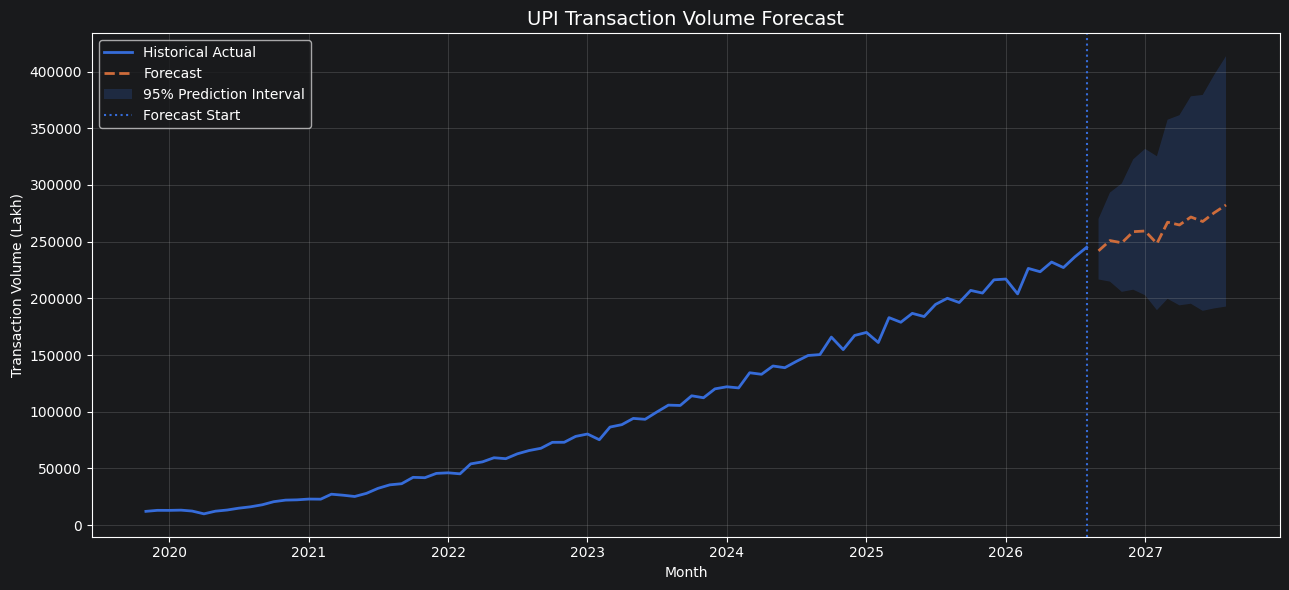

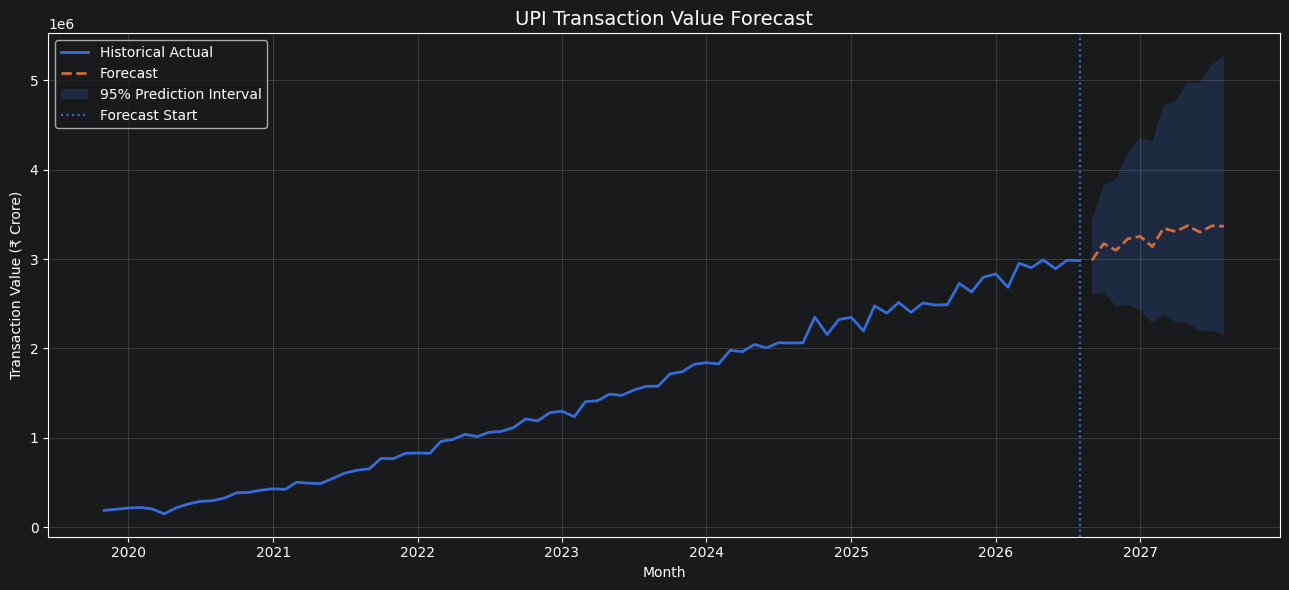

In [116]:
import matplotlib.pyplot as plt

for col, fitted in final_seasonal_models.items():

    actual = ts_df[col]
    forecast_df = forecast_results[col]

    plt.figure(figsize=(13, 6))

    # Historical observations
    plt.plot(
        actual.index,
        actual.values,
        label="Historical Actual",
        linewidth=2
    )

    # Forecast
    plt.plot(
        forecast_df["Date"],
        forecast_df["Forecast"],
        label="Forecast",
        linewidth=2,
        linestyle="--"
    )

    # 95% prediction interval
    plt.fill_between(
        forecast_df["Date"],
        forecast_df["Lower_95"],
        forecast_df["Upper_95"],
        alpha=0.2,
        label="95% Prediction Interval"
    )

    # Forecast starting point
    plt.axvline(
        actual.index[-1],
        linestyle=":",
        label="Forecast Start"
    )

    # Chart formatting
    title = (
        "UPI Transaction Volume Forecast"
        if col == "UPI_Volume_Lakh"
        else "UPI Transaction Value Forecast"
    )

    plt.title(title, fontsize=14)
    plt.xlabel("Month")
    plt.ylabel(
        "Transaction Volume (Lakh)"
        if col == "UPI_Volume_Lakh"
        else "Transaction Value (₹ Crore)"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.show()


In [117]:
plt.savefig(
    "../visualisations/upi_volume_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [118]:
import os

print("Current working directory:", os.getcwd())
print("Available folders:", os.listdir())

Current working directory: C:\Users\preet\PycharmProjects\WelcomeScreen
Available folders: ['.idea', '.venv', '01_data_understanding.ipynb', '02_exploratory_data_analysis.ipynb', 'annual_average_retail_sales.png', 'data', 'monthly_retail_sales_trend.png', 'Retail_Sales_Analysis.py', 'retail_sales_volatility.png', 'retail_yoy_growth.png', 'yoy_growth.png', 'yoy_growth_analysis.png']


In [119]:
import os

os.makedirs("../visualisations", exist_ok=True)

In [120]:
plt.savefig(
    "../visualisations/upi_volume_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [121]:
plt.savefig(
    "../visualisations/upi_value_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

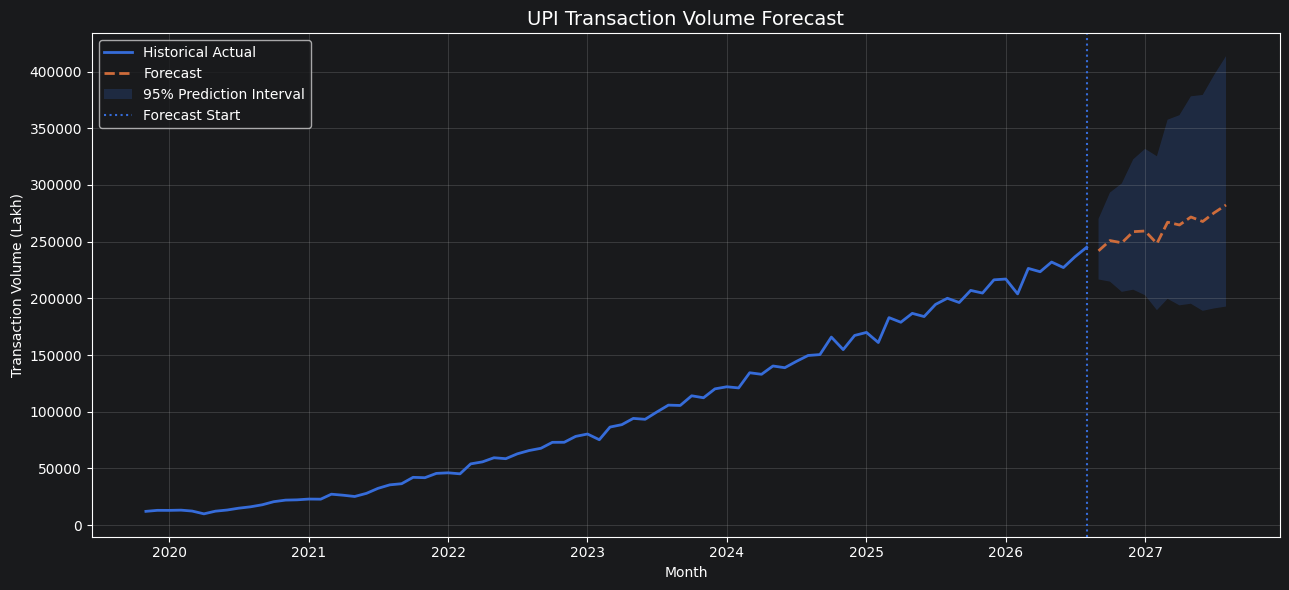

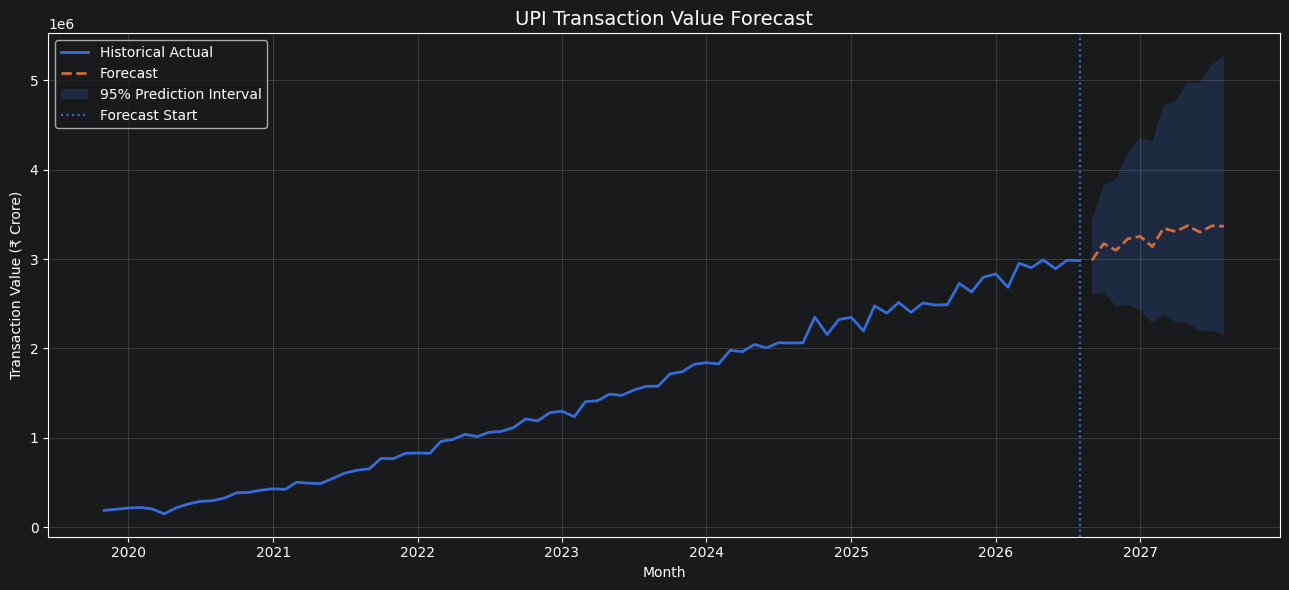

In [122]:
import matplotlib.pyplot as plt

for col, fitted in final_seasonal_models.items():

    actual = ts_df[col]
    forecast_df = forecast_results[col]

    plt.figure(figsize=(13, 6))

    # Historical observations
    plt.plot(
        actual.index,
        actual.values,
        label="Historical Actual",
        linewidth=2
    )

    # Forecast
    plt.plot(
        forecast_df["Date"],
        forecast_df["Forecast"],
        label="Forecast",
        linewidth=2,
        linestyle="--"
    )

    # 95% prediction interval
    plt.fill_between(
        forecast_df["Date"],
        forecast_df["Lower_95"],
        forecast_df["Upper_95"],
        alpha=0.2,
        label="95% Prediction Interval"
    )

    # Forecast starting point
    plt.axvline(
        actual.index[-1],
        linestyle=":",
        label="Forecast Start"
    )

    # Chart formatting
    title = (
        "UPI Transaction Volume Forecast"
        if col == "UPI_Volume_Lakh"
        else "UPI Transaction Value Forecast"
    )

    plt.title(title, fontsize=14)
    plt.xlabel("Month")
    plt.ylabel(
        "Transaction Volume (Lakh)"
        if col == "UPI_Volume_Lakh"
        else "Transaction Value (₹ Crore)"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()


    plt.savefig(
    "../visualisations/upi_volume_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

    plt.savefig(
    "../visualisations/upi_value_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

    plt.show()


In [123]:
#Analyzing IMPS and NEFT together.

In [124]:
imps_neft_cols = [
    "IMPS_Volume_Lakh",
    "IMPS_Value_Crore",
    "NEFT_Volume_Lakh",
    "NEFT_Value_Crore"
]

imps_neft_summary = df[imps_neft_cols].describe().T

display(imps_neft_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
IMPS_Volume_Lakh,82.0,4045.73,963.67,1224.75,3543.62,4354.22,4741.05,5806.36
IMPS_Value_Crore,82.0,469980.82,161128.48,121140.79,321176.27,503989.60,600549.04,740176.18
NEFT_Volume_Lakh,82.0,5481.28,2419.39,1759.79,3253.93,4875.74,7972.20,9390.43
NEFT_Value_Crore,82.0,3089521.79,901790.93,1306406.41,2340789.54,3042909.59,3780130.35,5661604.25


In [125]:
##Initial observations:
# NEFT has a higher average monthly transaction volume than IMPS.
# NEFT also handles substantially higher transaction value.
# IMPS transaction volume has a relatively high standard deviation compared with its mean.
# NEFT's maximum transaction volume is substantially higher than its minimum.

In [126]:
df["IMPS_Avg_Txn_Rs"] = (
    df["IMPS_Value_Crore"] * 100
    / df["IMPS_Volume_Lakh"]
)

df["NEFT_Avg_Txn_Rs"] = (
    df["NEFT_Value_Crore"] * 100
    / df["NEFT_Volume_Lakh"]
)

avg_transaction_summary = df[
    ["IMPS_Avg_Txn_Rs", "NEFT_Avg_Txn_Rs"]
].describe().T

display(avg_transaction_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
IMPS_Avg_Txn_Rs,82.0,11576.19,3280.49,8152.39,9318.43,10487.34,13398.40,20241.15
NEFT_Avg_Txn_Rs,82.0,61523.70,13160.02,43514.76,49887.27,59646.63,71690.57,87734.11


In [127]:
#monthly trend comparison

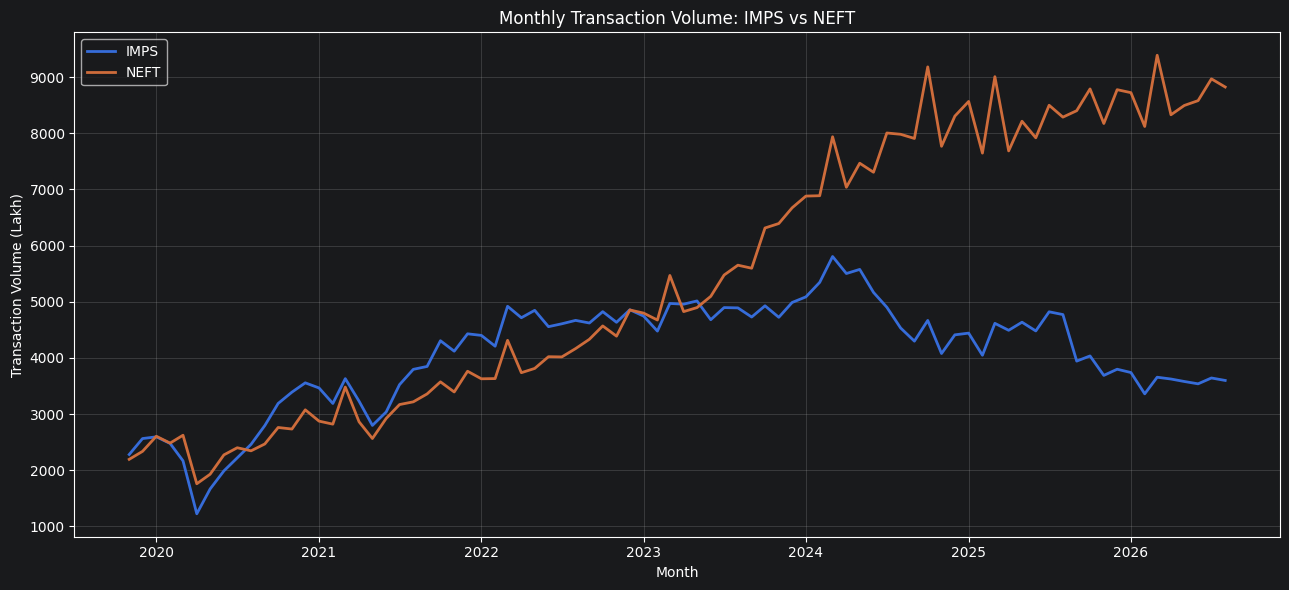

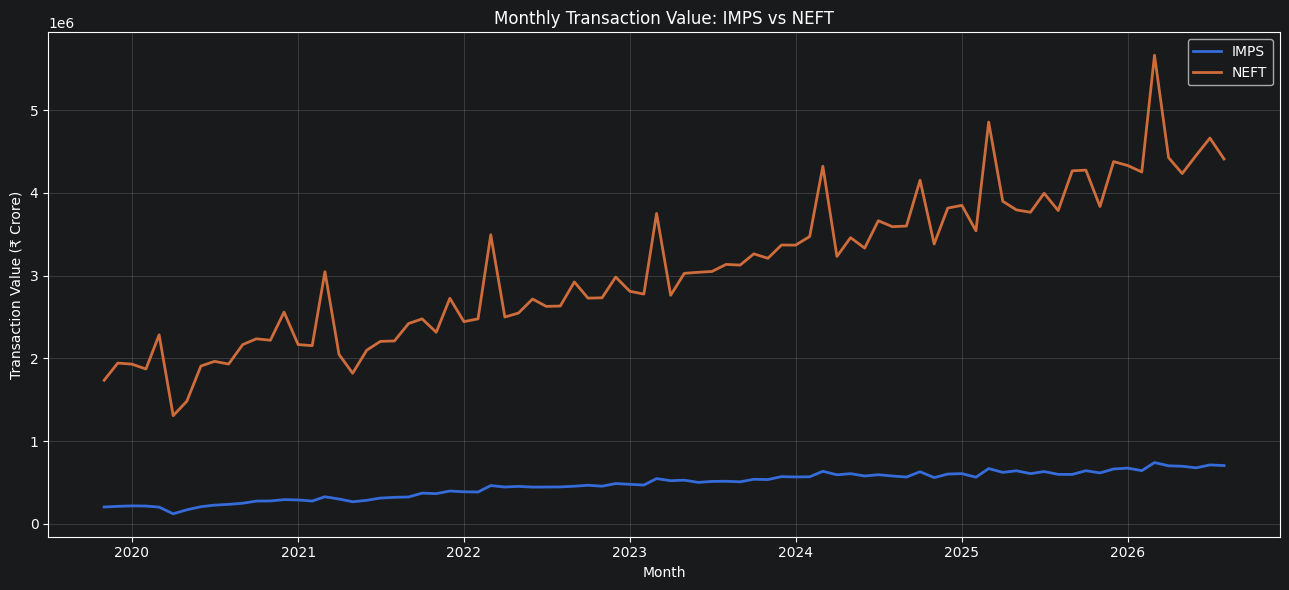

In [128]:
import matplotlib.pyplot as plt

# Transaction volume comparison
plt.figure(figsize=(13, 6))

plt.plot(
    df["Date"],
    df["IMPS_Volume_Lakh"],
    label="IMPS",
    linewidth=2
)

plt.plot(
    df["Date"],
    df["NEFT_Volume_Lakh"],
    label="NEFT",
    linewidth=2
)

plt.title("Monthly Transaction Volume: IMPS vs NEFT")
plt.xlabel("Month")
plt.ylabel("Transaction Volume (Lakh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "../visualisations/imps_neft_volume_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Transaction value comparison
plt.figure(figsize=(13, 6))

plt.plot(
    df["Date"],
    df["IMPS_Value_Crore"],
    label="IMPS",
    linewidth=2
)

plt.plot(
    df["Date"],
    df["NEFT_Value_Crore"],
    label="NEFT",
    linewidth=2
)

plt.title("Monthly Transaction Value: IMPS vs NEFT")
plt.xlabel("Month")
plt.ylabel("Transaction Value (₹ Crore)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "../visualisations/imps_neft_value_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [129]:
growth_comparison = pd.DataFrame({
    "Payment_System": ["IMPS", "NEFT"],

    "Volume_Change_Percent": [
        (df["IMPS_Volume_Lakh"].iloc[-1] /
         df["IMPS_Volume_Lakh"].iloc[0] - 1) * 100,

        (df["NEFT_Volume_Lakh"].iloc[-1] /
         df["NEFT_Volume_Lakh"].iloc[0] - 1) * 100
    ],

    "Value_Change_Percent": [
        (df["IMPS_Value_Crore"].iloc[-1] /
         df["IMPS_Value_Crore"].iloc[0] - 1) * 100,

        (df["NEFT_Value_Crore"].iloc[-1] /
         df["NEFT_Value_Crore"].iloc[0] - 1) * 100
    ]
})

display(growth_comparison.round(2))

,Payment_System,Volume_Change_Percent,Value_Change_Percent
0,IMPS,57.82,246.83
1,NEFT,302.13,154.15


In [130]:
# Observations

#Between November 2019 and August 2026, IMPS and NEFT demonstrated different growth patterns. IMPS transaction volume increased by 57.82%, while transaction value rose by 246.83%, indicating substantially faster growth in transaction value. In contrast, NEFT transaction volume expanded by 302.13%, exceeding its transaction value growth of 154.15%. These differences suggest changing transaction characteristics across the two payment systems, with IMPS experiencing stronger growth in value relative to volume and NEFT experiencing stronger growth in transaction frequency.

In [131]:
#Calculate CAGR

In [132]:
years = (
    (df["Date"].iloc[-1] - df["Date"].iloc[0]).days / 365.25
)

indicators = [
    "IMPS_Volume_Lakh",
    "IMPS_Value_Crore",
    "NEFT_Volume_Lakh",
    "NEFT_Value_Crore"
]

cagr_results = []

for col in indicators:
    start = df[col].iloc[0]
    end = df[col].iloc[-1]

    cagr = ((end / start) ** (1 / years) - 1) * 100

    cagr_results.append({
        "Indicator": col,
        "CAGR_Percent": cagr
    })

imps_neft_cagr = pd.DataFrame(cagr_results)

display(imps_neft_cagr.round(2))

,Indicator,CAGR_Percent
0,IMPS_Volume_Lakh,6.99
1,IMPS_Value_Crore,20.23
2,NEFT_Volume_Lakh,22.90
3,NEFT_Value_Crore,14.82


In [133]:
comparison_means = pd.DataFrame({
    "Payment_System": ["UPI", "IMPS", "NEFT"],

    "Mean_Monthly_Volume_Lakh": [
        df["UPI_Volume_Lakh"].mean(),
        df["IMPS_Volume_Lakh"].mean(),
        df["NEFT_Volume_Lakh"].mean()
    ],

    "Mean_Monthly_Value_Crore": [
        df["UPI_Value_Crore"].mean(),
        df["IMPS_Value_Crore"].mean(),
        df["NEFT_Value_Crore"].mean()
    ]
})

display(comparison_means.round(2))

,Payment_System,Mean_Monthly_Volume_Lakh,Mean_Monthly_Value_Crore
0,UPI,101640.29,1459787.06
1,IMPS,4045.73,469980.82
2,NEFT,5481.28,3089521.79


In [134]:
avg_txn_comparison = pd.DataFrame({
    "Payment_System": ["UPI", "IMPS", "NEFT"],

    "Average_Transaction_Rs": [
        df["UPI_Value_Crore"].sum() * 100 /
        df["UPI_Volume_Lakh"].sum(),

        df["IMPS_Value_Crore"].sum() * 100 /
        df["IMPS_Volume_Lakh"].sum(),

        df["NEFT_Value_Crore"].sum() * 100 /
        df["NEFT_Volume_Lakh"].sum()
    ]
})

display(avg_txn_comparison.round(2))

,Payment_System,Average_Transaction_Rs
0,UPI,1436.23
1,IMPS,11616.70
2,NEFT,56365.00


In [135]:
# Combined monthly transaction volume
df["Total_Volume_Lakh"] = (
    df["UPI_Volume_Lakh"]
    + df["IMPS_Volume_Lakh"]
    + df["NEFT_Volume_Lakh"]
)

# Combined monthly transaction value
df["Total_Value_Crore"] = (
    df["UPI_Value_Crore"]
    + df["IMPS_Value_Crore"]
    + df["NEFT_Value_Crore"]
)

# Volume market shares
for system in ["UPI", "IMPS", "NEFT"]:
    df[f"{system}_Volume_Share"] = (
        df[f"{system}_Volume_Lakh"]
        / df["Total_Volume_Lakh"]
    ) * 100

# Value market shares
for system in ["UPI", "IMPS", "NEFT"]:
    df[f"{system}_Value_Share"] = (
        df[f"{system}_Value_Crore"]
        / df["Total_Value_Crore"]
    ) * 100

In [136]:
share_summary = df[
    [
        "UPI_Volume_Share",
        "IMPS_Volume_Share",
        "NEFT_Volume_Share",
        "UPI_Value_Share",
        "IMPS_Value_Share",
        "NEFT_Value_Share"
    ]
].agg(["mean", "min", "max"]).T

display(share_summary.round(2))

,mean,min,max
UPI_Volume_Share,87.34,71.50,95.18
IMPS_Volume_Share,6.04,1.40,14.26
NEFT_Volume_Share,6.61,3.43,15.20
UPI_Value_Share,25.93,7.67,37.76
IMPS_Value_Share,9.49,7.50,11.32
NEFT_Value_Share,64.58,53.45,84.83


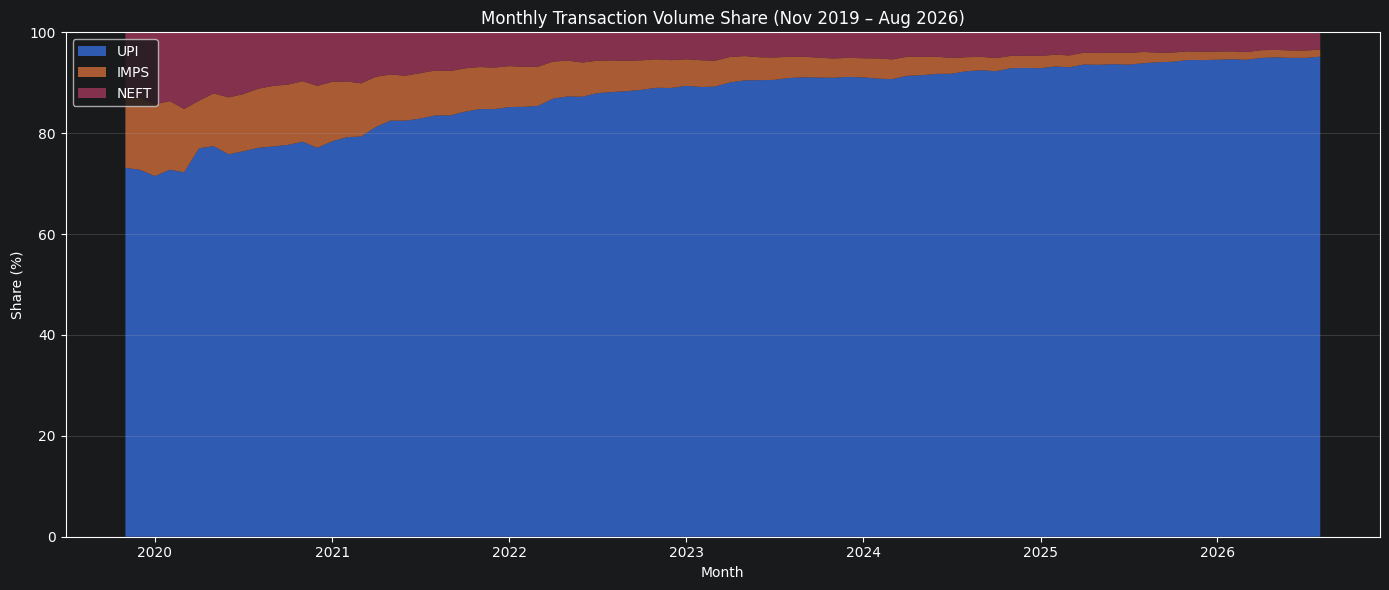

In [137]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.stackplot(
    df["Date"],
    df["UPI_Volume_Share"],
    df["IMPS_Volume_Share"],
    df["NEFT_Volume_Share"],
    labels=["UPI", "IMPS", "NEFT"],
    alpha=0.8
)

plt.title("Monthly Transaction Volume Share (Nov 2019 – Aug 2026)")
plt.xlabel("Month")
plt.ylabel("Share (%)")
plt.ylim(0, 100)
plt.legend(loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../visualisations/payment_volume_share.png", dpi=300)
plt.show()

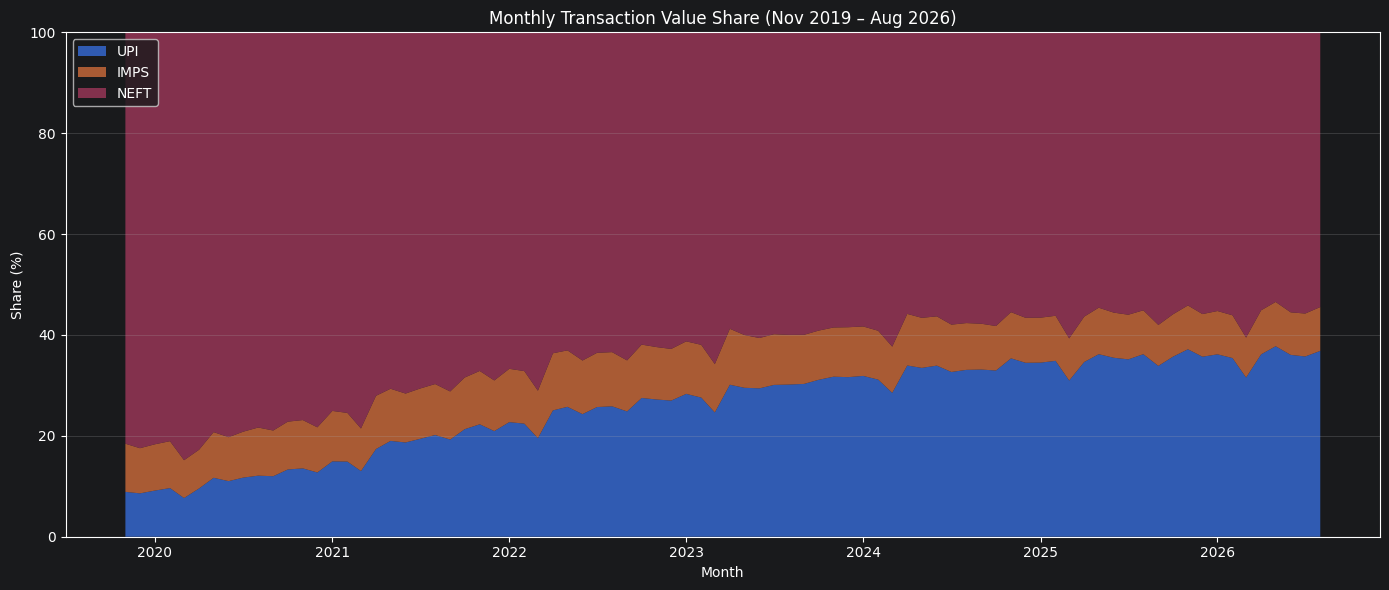

In [138]:
plt.figure(figsize=(14, 6))

plt.stackplot(
    df["Date"],
    df["UPI_Value_Share"],
    df["IMPS_Value_Share"],
    df["NEFT_Value_Share"],
    labels=["UPI", "IMPS", "NEFT"],
    alpha=0.8
)

plt.title("Monthly Transaction Value Share (Nov 2019 – Aug 2026)")
plt.xlabel("Month")
plt.ylabel("Share (%)")
plt.ylim(0, 100)
plt.legend(loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../visualisations/payment_value_share.png", dpi=300)
plt.show()

In [139]:
print(df.columns.tolist())

['Date', 'IMPS_Volume_Lakh', 'IMPS_Value_Crore', 'NEFT_Volume_Lakh', 'NEFT_Value_Crore', 'UPI_Volume_Lakh', 'UPI_Value_Crore', 'IMPS_Avg_Txn_Rs', 'NEFT_Avg_Txn_Rs', 'Total_Volume_Lakh', 'Total_Value_Crore', 'UPI_Volume_Share', 'IMPS_Volume_Share', 'NEFT_Volume_Share', 'UPI_Value_Share', 'IMPS_Value_Share', 'NEFT_Value_Share']


In [140]:
# Recalculate volume shares
total_volume = (
    df["UPI_Volume_Lakh"]
    + df["IMPS_Volume_Lakh"]
    + df["NEFT_Volume_Lakh"]
)

for system in ["UPI", "IMPS", "NEFT"]:
    df[f"{system}_Volume_Share"] = (
        df[f"{system}_Volume_Lakh"] / total_volume
    ) * 100


# Recalculate value shares
total_value = (
    df["UPI_Value_Crore"]
    + df["IMPS_Value_Crore"]
    + df["NEFT_Value_Crore"]
)

for system in ["UPI", "IMPS", "NEFT"]:
    df[f"{system}_Value_Share"] = (
        df[f"{system}_Value_Crore"] / total_value
    ) * 100

In [141]:
share_columns = [
    "UPI_Volume_Share",
    "IMPS_Volume_Share",
    "NEFT_Volume_Share",
    "UPI_Value_Share",
    "IMPS_Value_Share",
    "NEFT_Value_Share"
]

share_change = pd.DataFrame({
    "Nov_2019": df[share_columns].iloc[0].values,
    "Aug_2026": df[share_columns].iloc[-1].values
}, index=share_columns)

share_change["Change_pp"] = (
    share_change["Aug_2026"] - share_change["Nov_2019"]
)

display(share_change.round(2))

,Nov_2019,Aug_2026,Change_pp
UPI_Volume_Share,73.14,95.18,22.03
IMPS_Volume_Share,13.69,1.40,-12.29
NEFT_Volume_Share,13.17,3.43,-9.74
UPI_Value_Share,8.90,36.84,27.95
IMPS_Value_Share,9.54,8.69,-0.85
NEFT_Value_Share,81.56,54.46,-27.10


In [142]:
#Finding 1 — UPI's dominance in transaction volume

#UPI's share increased from 73.14% to 95.18%, a gain of approximately 22 percentage points. By August 2026, UPI accounted for more than 95% of the combined transaction volume of the three analysed systems.

In [143]:
# Finding 2 — UPI's growing importance in transaction value

# UPI's value share increased from 8.90% to 36.84%. This is a substantial shift in the composition of transaction value.

In [144]:
#Finding 3 — Declining relative share of IMPS

#IMPS experienced a significant decline in volume share, from 13.69% to 1.40%. Its value share, however, declined only slightly.

In [145]:
#Finding 4 — NEFT remains important for transaction value

#NEFT's value share decreased from 81.56% to 54.46%, but it still accounted for more than half of the combined transaction value in August 2026.

In [146]:
#Research and analytical interpretation

In [147]:
#The evidence indicates a substantial change in the composition of India's payment activity across these three systems between November 2019 and August 2026.
#UPI increasingly dominates transaction frequency and has gained considerable importance in transaction value. NEFT continues to account for a large proportion of transaction value despite losing relative share. IMPS has experienced the sharpest relative decline in transaction volume.

#These findings are descriptive. They do not establish that UPI growth caused the decline in IMPS or NEFT shares.

## 9. Key Findings and Discussion

### 9.1 Expansion of Digital Payment Activity

The analysis of monthly payment-system indicators from November 2019 to August 2026 reveals substantial growth in the activity of UPI, IMPS and NEFT. Among the three systems, UPI recorded the highest compound annual growth rates in both transaction volume and transaction value, at approximately 56.00% and 50.47%, respectively.

IMPS recorded a volume CAGR of approximately 6.99% and a value CAGR of 20.23%. NEFT recorded a volume CAGR of approximately 22.90% and a value CAGR of 14.82%. These differences indicate that the three payment systems experienced distinct growth patterns during the observation period.

### 9.2 Differences in Transaction Volume and Value

UPI recorded the highest average monthly transaction volume, approximately 101,640 lakh transactions. NEFT recorded the highest average monthly transaction value, approximately ₹3,089,522 crore.

The results highlight an important distinction between transaction frequency and transaction value. UPI is associated with substantially higher transaction frequency, whereas NEFT accounts for a considerably larger average monthly transaction value.

### 9.3 Average Transaction Size

The volume-weighted average transaction sizes were approximately:

- UPI: ₹1,436.23
- IMPS: ₹11,616.70
- NEFT: ₹56,365.00

NEFT recorded the highest average transaction size, followed by IMPS and UPI. This suggests differences in the typical transaction values processed through the three systems. These figures are aggregate averages and should not be interpreted as the distribution of individual transaction sizes.

### 9.4 Changes in Relative Transaction Composition

The composition analysis demonstrates a substantial shift towards UPI within the three payment systems examined.

UPI's average monthly transaction-volume share was 87.34%. Its share increased from 73.14% in November 2019 to 95.18% in August 2026, representing a gain of approximately 22.03 percentage points.

UPI's transaction-value share increased from 8.90% to 36.84%, a gain of approximately 27.95 percentage points.

Over the same period, IMPS volume share declined from 13.69% to 1.40%, while NEFT volume share declined from 13.17% to 3.43%. NEFT nevertheless remained the largest contributor to combined transaction value in August 2026, accounting for 54.46%.

These results indicate that UPI's role expanded considerably in both transaction frequency and value, while NEFT continued to account for a substantial proportion of the combined transaction value.

### 9.5 Forecasting Results

Seasonal ARIMA models were selected using expanding-window rolling-origin validation. The selected models were SARIMA(0,1,0)(1,0,0,12) for UPI transaction volume and SARIMA(1,1,0)(1,0,0,12) for UPI transaction value.

The forecasts cover September 2026 to August 2027. The point forecasts suggest an increase from approximately 241,879 lakh to 282,326 lakh transactions in monthly UPI volume, and from approximately ₹2,984,921 crore to ₹3,366,908 crore in monthly UPI value.

These endpoint comparisons represent changes across the forecast horizon, not year-over-year growth rates. Residual diagnostics identified remaining autocorrelation, non-normality and heteroskedasticity. Therefore, the forecasts should be interpreted as indicative projections rather than precise predictions.

### 9.6 Overall Interpretation

Taken together, the findings demonstrate a significant change in the relative composition of the three payment systems during the study period. UPI emerged as the dominant system in transaction frequency and increased its contribution to transaction value. NEFT retained a substantial role in transaction value, while IMPS experienced a marked decline in its relative transaction-volume share.

The analysis is descriptive and predictive. It does not establish causal relationships between the growth of one payment system and changes in the activity of another.